In [ ]:
# ============================================================
# CELL 1: IMPORTS, DEVICE, GLOBAL CONFIG  (Kaggle)
# ============================================================
import os, sys, json, math, time, random, gc, re, heapq, pickle, copy, warnings, contextlib
import multiprocessing as mp
from functools import partial
from pathlib import Path
from dataclasses import dataclass, asdict, replace
from collections import Counter

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.special import logsumexp
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from tqdm.auto import tqdm as _tqdm

warnings.filterwarnings("ignore")
tqdm = partial(_tqdm, bar_format="{l_bar}{bar}| {n_fmt}/{total_fmt}")      # progress bars without elapsed/ETA

SEED = 42
def seed_everything(s=SEED):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything()

assert torch.cuda.is_available(), "Enable a GPU accelerator in Kaggle settings."
device = torch.device("cuda")
GPU = torch.cuda.get_device_properties(0)
USE_BF16 = GPU.major >= 8
AMP_DTYPE = torch.bfloat16 if USE_BF16 else torch.float16
USE_SCALER = not USE_BF16
torch.backends.cuda.matmul.allow_tf32 = True

# ---------------- paths (Kaggle) ----------------
OUT_DIR = Path("/kaggle/working/pcr_mla_qlora"); OUT_DIR.mkdir(parents=True, exist_ok=True)
KAGGLE_INPUT = Path("/kaggle/input")
DATA_DIR = Path("/kaggle/working/Phase_7_PCR")
REPO_ID = "Exploration-Lab/CS-781-Capstone"      # only used if Phase_7_PCR is not already on disk
HF_TOKEN = ""            # <- paste your Hugging Face token here, OR leave empty and add a Kaggle Secret named HF_TOKEN (Add-ons > Secrets)
# >>> set these two to where your Phase 1 MLA checkpoint / tokenizer live (if the exact path is wrong, the notebook searches /kaggle/input)
CKPT_PATH = KAGGLE_INPUT / "datasets/vishwaspathania/mla-p123/best_model.pt"
TOK_PATH  = KAGGLE_INPUT / "datasets/vishwaspathania/tokenizersss/legal_bpe_a1_50k_final.json"

def locate_artifact(path, pattern, must_contain=None):
    if path.is_file(): return path
    matches = [m for m in KAGGLE_INPUT.rglob(pattern)]
    if must_contain:
        matches = [m for m in matches if must_contain.lower() in str(m).lower()]
    if len(matches) == 1: return matches[0]
    raise FileNotFoundError(f"{pattern}: {len(matches)} matches under /kaggle/input {[str(m) for m in matches]}; set the exact path above.")

CKPT_PATH = locate_artifact(CKPT_PATH, "*.pt", must_contain="mla")
TOK_PATH  = locate_artifact(TOK_PATH, "legal_bpe_a1_50k_final.json")

# ---------------- document / chunk settings (chunk length is read from the checkpoint in CELL 3: 512, as in Exp. 1) ----------------
ADD_EOS = True                 # append </s> to every chunk (as in Exp. 1)
MAX_DOC_TOKENS = 65_536
MAX_CHARS_PER_DOC = 220_000

# ---------------- protocol: Exp. 1 winner, nothing is searched ----------------
TOP_K = 7
RESUME = True
FINAL_EPOCHS = 6
ZERO_EVAL_CHUNKS = 12          # zero-shot baselines on dev
FINAL_EVAL_CHUNKS = 32         # dev evaluation after every epoch (model selection)
TEST_EVAL_CHUNKS = 48          # final dev analysis + test inference
BATCH_Q = 17                   # queries / step selected in Exp. 1 (17 x 11 = 187 chunks of 512 tokens)
INFER_BS = 128                 # fixed inference batch (chunks); raise to 192 if you have memory, lower if OOM
RUN_ZERO_SHOT = True
RUN_CAP_ABLATION = True

# ---------------- added from the improved GQA notebook ----------------
MS_WEIGHT = 0.5                # weight of the chunk-MaxSim InfoNCE term (0 = old mean-vector loss only)
EMA_DECAY = 0.98               # EMA of the LoRA adapters (evaluated + saved)
USE_CALIBRATION = True         # pool-aware, label-free score calibration across the queries of a split

# ---------------- QLoRA hyper-parameters (see the markdown above) ----------------
NF4_BLOCK = 64                 # quantisation block (assignment: block_size=64)
DQ_BLOCK = 256                 # blocks sharing one second-level (double-quant) scale
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.0
LORA_TARGETS = "all"           # "all" (every block linear) or "qv" (assignment setting: q_proj + v_up_proj)
LORA_LR = 2e-4

print("AMP dtype:", AMP_DTYPE, "| GradScaler:", USE_SCALER, "| output dir:", OUT_DIR)

AMP dtype: torch.float16 | GradScaler: True | output dir: /kaggle/working/pcr_mla_qlora


In [2]:
# ============================================================
# CELL 2: LOAD PHASE 7 DATA (queries + per-split candidate pools)
# ============================================================
SPLITS = ["train", "dev", "test"]
FILES = {
    "train": ("Train/train.json", "Train/train_candidates.json"),
    "dev":   ("Dev/dev.json",     "Dev/dev_candidates.json"),
    "test":  ("Test/test.json",   "Test/test_candidates.json"),
}

def find_pcr_root():
    for c in [DATA_DIR / "Phase_7_PCR", DATA_DIR]:
        if (c / "Train" / "train.json").exists():
            return c
    if KAGGLE_INPUT.exists():
        for m in KAGGLE_INPUT.rglob("train.json"):
            if m.parent.name == "Train":
                return m.parent.parent
    return None

PCR_ROOT = find_pcr_root()
if PCR_ROOT is None:
    from huggingface_hub import hf_hub_download
    token = HF_TOKEN or os.environ.get("HF_TOKEN")
    if not token:
        try:
            from kaggle_secrets import UserSecretsClient
            token = UserSecretsClient().get_secret("HF_TOKEN")
        except Exception:
            token = None
    assert token, "Dataset not found on disk: set HF_TOKEN in CELL 1 or add a Kaggle Secret named HF_TOKEN."
    for qf, cf in FILES.values():
        for f in (qf, cf):
            hf_hub_download(repo_id=REPO_ID, filename=f"Phase_7_PCR/{f}", repo_type="dataset", token=token, local_dir=str(DATA_DIR))
    PCR_ROOT = DATA_DIR / "Phase_7_PCR"
print("Data root:", PCR_ROOT)

def norm_text(value):
    if isinstance(value, list):
        t = " ".join(str(s) for s in value if s is not None and str(s).strip())
    else:
        t = str(value or "")
    return " ".join(t.split())[:MAX_CHARS_PER_DOC].rstrip()

DOC_TEXT = {}
QKEYS, CKEYS, REL = {}, {}, {}
for split in SPLITS:
    qf, cf = FILES[split]
    queries = json.load(open(PCR_ROOT / qf, encoding="utf-8"))
    cands   = json.load(open(PCR_ROOT / cf, encoding="utf-8"))
    QKEYS[split], CKEYS[split], REL[split] = [], [], {}
    for cid, rec in cands.items():
        k = f"{split}|c|{cid}"
        DOC_TEXT[k] = norm_text(rec["text"]) or "empty"
        CKEYS[split].append(k)
    for qid, rec in queries.items():
        k = f"{split}|q|{qid}"
        DOC_TEXT[k] = norm_text(rec["text"]) or "empty"
        QKEYS[split].append(k)
        if "relevant_candidates" in rec:
            REL[split][k] = {f"{split}|c|{c}" for c in map(str, rec["relevant_candidates"])}
    del queries, cands
    if split != "test":
        pool = set(CKEYS[split])
        assert sum(len(r - pool) for r in REL[split].values()) == 0, f"{split}: relevant IDs outside pool"
    print(f"{split:5s}: {len(QKEYS[split]):4d} queries | {len(CKEYS[split]):5d} candidates")

def cid_of(key):
    return key.split("|", 2)[2]

# gold matrices (train / dev) aligned with QKEYS / CKEYS
GOLD = {}
for split in ("train", "dev"):
    ci = {k: i for i, k in enumerate(CKEYS[split])}
    G = np.zeros((len(QKEYS[split]), len(CKEYS[split])), bool)
    for i, q in enumerate(QKEYS[split]):
        for c in REL[split].get(q, ()): G[i, ci[c]] = True
    GOLD[split] = G
    print(f"{split}: {int(G.sum())} labels | pool docs relevant to >=1 query: {int((G.sum(0) > 0).sum())}/{G.shape[1]}")

Phase_7_PCR/Train/train.json: reconstructing file:   0%|          |  0.00B / 33.2MB            

Phase_7_PCR/Train/train.json: downloading bytes:           |  0.00B            

Phase_7_PCR/Train/train_candidates.json: reconstructing file:   0%|          |  0.00B /  160MB            

Phase_7_PCR/Train/train_candidates.json: downloading bytes:           |  0.00B            

dev.json:   0%|          | 0.00/5.87M [00:00<?, ?B/s]

Phase_7_PCR/Dev/dev_candidates.json: reconstructing file:   0%|          |  0.00B / 51.9MB            

Phase_7_PCR/Dev/dev_candidates.json: downloading bytes:           |  0.00B            

test.json:   0%|          | 0.00/9.34M [00:00<?, ?B/s]

Phase_7_PCR/Test/test_candidates.json: reconstructing file:   0%|          |  0.00B / 71.1MB            

Phase_7_PCR/Test/test_candidates.json: downloading bytes:           |  0.00B            

Data root: /kaggle/working/Phase_7_PCR/Phase_7_PCR
train:  827 queries |  4320 candidates
dev  :  118 queries |  1023 candidates
test :  237 queries |  1727 candidates
train: 5308 labels | pool docs relevant to >=1 query: 4107/4320
dev: 973 labels | pool docs relevant to >=1 query: 920/1023


In [3]:
# ============================================================
# CELL 3: PHASE 1 TOKENIZER + MLA CHECKPOINT + CHUNK SETTINGS
# ============================================================
N_SPECIAL = 4; N_BYTES = 256; BASE_VOCAB_SIZE = N_SPECIAL + N_BYTES
PAD_ID, UNK_ID, BOS_ID, EOS_ID = 0, 1, 2, 3
SPACE_ID = N_SPECIAL + 32
SPECIAL_TOKENS = ["<pad>", "<unk>", "<s>", "</s>"]

class A1Tokenizer:
    def __init__(self, itos, merges):
        self.itos = list(itos)
        self.merges = [tuple(m) for m in merges]
        self.vocab_size = len(self.itos)
        self._byte_to_id = {bytes([b]): N_SPECIAL + b for b in range(256)}
        self._merge_ranks = {pair: r for r, pair in enumerate(self.merges)}
        self._cache = {}

    def _encode_word(self, word):
        raw = word.encode("utf-8")
        seq = [self._byte_to_id[bytes([b])] for b in raw]
        if len(seq) < 2 or not self._merge_ranks:
            return seq
        n = len(seq)
        prev = [-1] + list(range(0, n - 1)); nxt = list(range(1, n)) + [-1]
        active = [True] * n; heap = []
        for i in range(n - 1):
            rank = self._merge_ranks.get((seq[i], seq[i + 1]))
            if rank is not None:
                heapq.heappush(heap, (rank, i, i + 1))
        while heap:
            rank, left, right = heapq.heappop(heap)
            if not active[left] or not active[right]: continue
            if nxt[left] != right or prev[right] != left: continue
            if self._merge_ranks.get((seq[left], seq[right])) != rank: continue
            seq[left] = BASE_VOCAB_SIZE + rank
            active[right] = False
            right_next = nxt[right]; nxt[left] = right_next
            if right_next != -1: prev[right_next] = left
            left_prev = prev[left]
            if left_prev != -1:
                nr = self._merge_ranks.get((seq[left_prev], seq[left]))
                if nr is not None: heapq.heappush(heap, (nr, left_prev, left))
            if right_next != -1:
                nr = self._merge_ranks.get((seq[left], seq[right_next]))
                if nr is not None: heapq.heappush(heap, (nr, left, right_next))
        out = []; i = 0
        while i != -1:
            if active[i]: out.append(seq[i])
            i = nxt[i]
        return out

    def encode_normalized(self, text):
        out = []; first = True
        for word in text.split(" "):
            if not first: out.append(SPACE_ID)
            first = False
            ids = self._cache.get(word)
            if ids is None:
                ids = self._encode_word(word)
                if len(self._cache) > 1_500_000: self._cache.clear()
                self._cache[word] = ids
            out.extend(ids)
        return out

P1 = torch.load(CKPT_PATH, map_location="cpu", weights_only=False, mmap=True)
tokenizer_payload = json.load(open(TOK_PATH, "r", encoding="utf-8"))
TOK = A1Tokenizer(tokenizer_payload["itos"], tokenizer_payload["merges"])
assert TOK.vocab_size == 50000 and TOK.itos[:4] == SPECIAL_TOKENS

print("Phase 1 checkpoint:", CKPT_PATH.name, "| step:", P1.get("global_step"), "| best val loss:", P1.get("best_val_loss"))
print("model config:", P1["model_config"])
_sd_keys = list(P1["model_state_dict"])
assert any(".attn.kv_down_proj." in k for k in _sd_keys), "this is not the MLA checkpoint (no attn.kv_down_proj keys)"
assert "kv_latent_dim" in P1["model_config"], "this is not the MLA checkpoint (no kv_latent_dim in model_config)"

# ---- chunk geometry follows the MLA context (512 = same as the GQA model of Exp. 1) ----
CHUNK_LEN    = P1["model_config"]["max_seq_len"]          # 512
CHUNK_STRIDE = int(CHUNK_LEN * 0.875)                      # 448 (12.5 % overlap)
CONTENT_LEN  = CHUNK_LEN - 1 if ADD_EOS else CHUNK_LEN
MIN_TAIL     = CHUNK_LEN // 8                              # 64
print(f"chunk length {CHUNK_LEN} | content {CONTENT_LEN} | stride {CHUNK_STRIDE} | min tail {MIN_TAIL}")
assert CHUNK_LEN == 512, "Exp. 1 settings (caps, stride, batch) were tuned for 512-token chunks"

Phase 1 checkpoint: best_model_mla.pt | step: 15000 | best val loss: 1.5098708868026733
model config: {'vocab_size': 50000, 'd_model': 768, 'n_layers': 16, 'n_heads': 12, 'kv_latent_dim': 192, 'd_ff': 2048, 'max_seq_len': 512, 'rope_base': 10000.0, 'rms_norm_eps': 1e-06, 'dropout': 0.0}
chunk length 512 | content 511 | stride 448 | min tail 64


In [4]:
# ============================================================
# CELL 4: PURE-PYTHON UTILITIES (chunking, metrics, BM25, fusion)
# ============================================================
def chunk_starts(n, chunk_len=None, stride=None):
    chunk_len = chunk_len or CONTENT_LEN; stride = stride or CHUNK_STRIDE
    if n <= chunk_len:
        return [0]
    last = n - chunk_len
    starts = list(range(0, last + 1, stride))
    if last - starts[-1] >= MIN_TAIL:
        starts.append(last)
    return starts

def make_chunk(tokens):
    return np.append(tokens, EOS_ID).astype(np.uint16) if ADD_EOS else tokens

def select_starts(n, max_chunks):
    st = chunk_starts(n)
    if max_chunks is None or len(st) <= max_chunks:
        return st
    idx = np.unique(np.linspace(0, len(st) - 1, max_chunks).round().astype(int))
    return [st[i] for i in idx]

def micro_prf(pred, gold, k=TOP_K):
    tp = npred = ngold = 0
    for q, g in gold.items():
        p = pred[q][:k]
        tp += len(set(p) & g); npred += len(p); ngold += len(g)
    P = tp / max(npred, 1); R = tp / max(ngold, 1)
    F1 = 2 * P * R / (P + R) if (P + R) > 0 else 0.0
    return {"P": P, "R": R, "F1": F1, "tp": tp}

def topk_keys(S, q_keys, c_keys, k=TOP_K):
    S = np.asarray(S)
    idx = np.argsort(-S, axis=1)[:, :k]
    return {q: [c_keys[j] for j in idx[i]] for i, q in enumerate(q_keys)}

def prf_from_scores(S, split):
    gold = REL[split]
    pred = topk_keys(S, QKEYS[split], CKEYS[split])
    return micro_prf(pred, {q: gold[q] for q in QKEYS[split] if q in gold})

def zscore(S):
    S = np.asarray(S, dtype=np.float32)
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-6)

_WORD = re.compile(r"[a-z0-9]+")
def bm25_matrix(q_keys, c_keys, k1=1.2, b=0.75, max_df_frac=0.5, min_len=3):
    def counts(key):
        return Counter(w for w in _WORD.findall(DOC_TEXT[key].lower()) if len(w) >= min_len)
    c_counts = [counts(k) for k in tqdm(c_keys, desc="bm25 pool", leave=False)]
    N = len(c_keys)
    df = Counter()
    for c in c_counts: df.update(c.keys())
    keep = [t for t, d in df.items() if d <= max_df_frac * N]
    vocab = {t: i for i, t in enumerate(keep)}
    idf = np.array([math.log(1 + (N - df[t] + 0.5) / (df[t] + 0.5)) for t in keep], dtype=np.float32)
    dl = np.array([sum(c.values()) for c in c_counts], dtype=np.float32); avg = max(float(dl.mean()), 1.0)
    indptr, indices, data = [0], [], []
    for i, c in enumerate(c_counts):
        norm = k1 * (1 - b + b * dl[i] / avg)
        for t, tf in c.items():
            j = vocab.get(t)
            if j is not None:
                indices.append(j); data.append(idf[j] * tf * (k1 + 1) / (tf + norm))
        indptr.append(len(indices))
    D = sp.csr_matrix((np.array(data, np.float32), np.array(indices, np.int32), np.array(indptr, np.int64)), shape=(N, len(vocab)))
    qindptr, qindices, qdata = [0], [], []
    for key in tqdm(q_keys, desc="bm25 queries", leave=False):
        for t, tf in counts(key).items():
            j = vocab.get(t)
            if j is not None:
                qindices.append(j); qdata.append(1.0 + math.log(tf))
        qindptr.append(len(qindices))
    Q = sp.csr_matrix((np.array(qdata, np.float32), np.array(qindices, np.int32), np.array(qindptr, np.int64)), shape=(len(q_keys), len(vocab)))
    return (Q @ D.T).toarray().astype(np.float32)

NEURAL_NAMES = ["mean", "maxsim", "maxsim_sym", "mean+maxsim_sym"]
def add_fusions(neural, bm25S=None):
    v = dict(neural)
    v["mean+maxsim_sym"] = zscore(neural["mean"]) + zscore(neural["maxsim_sym"])
    if bm25S is not None:
        v["bm25"] = bm25S
        for base in ("mean", "maxsim_sym"):
            for w in (0.25, 0.5, 1.0):
                v[f"{base}+{w}*bm25"] = zscore(neural[base]) + w * zscore(bm25S)
    return v

# ---------------- added from the improved GQA notebook: exact F1@7 on matrices, calibration ----------------
def f1_at7(S, Gm):
    # exact Micro-F1@7 for a score matrix S [nq, nc] against a boolean gold matrix Gm [nq, nc]
    idx = np.argpartition(-S, TOP_K - 1, axis=1)[:, :TOP_K]
    tp = np.take_along_axis(Gm, idx, 1).sum()
    P = tp / (TOP_K * S.shape[0]); R = tp / max(int(Gm.sum()), 1)
    return float(2 * P * R / (P + R)) if (P + R) > 0 else 0.0

def prf_at7(S, Gm):
    idx = np.argpartition(-S, TOP_K - 1, axis=1)[:, :TOP_K]
    tp = np.take_along_axis(Gm, idx, 1).sum()
    P = tp / (TOP_K * S.shape[0]); R = tp / max(int(Gm.sum()), 1)
    return {"P": float(P), "R": float(R), "F1": float(2 * P * R / (P + R)) if (P + R) > 0 else 0.0}

def rowz(S):
    S = np.asarray(S, dtype=np.float32)
    return (S - S.mean(1, keepdims=True)) / (S.std(1, keepdims=True) + 1e-6)

# ---- pool-aware calibration (label-free) -------------------------------------------------------
# Most pool documents are relevant to ~1 query, so a candidate that is much closer to ANOTHER query than to this one
# is probably not ours. 'dsm' = dual-softmax style penalty with strength alpha; 'csls' = hubness-reduced similarity.
def calibrate(Z, method="none", tau=0.5, alpha=0.5, k=10):
    if method == "none": return Z
    if method == "dsm":
        A = Z.astype(np.float64) / tau
        return (A - alpha * logsumexp(A, axis=0, keepdims=True)).astype(np.float32)
    if method == "csls":
        kk = max(1, min(k, Z.shape[0])); rc = np.sort(Z, axis=0)[-kk:].mean(0, keepdims=True)
        return (Z - alpha * rc).astype(np.float32)
    raise ValueError(method)

CAL_GRID = [("none", {})] + \
    [("dsm", dict(tau=t, alpha=a)) for t in (0.15, 0.3, 0.6, 1.0) for a in (0.25, 0.5, 0.75, 1.0, 1.25, 1.5)] + \
    [("csls", dict(k=k, alpha=a)) for k in (5, 10, 20) for a in (0.25, 0.5, 1.0)]

def cal_name(m, p): return m if m == "none" else m + "(" + ",".join(f"{k}={v}" for k, v in p.items()) + ")"

In [5]:
# ============================================================
# CELL 5: TOKENISE EVERY DOCUMENT ONCE + BM25 BASELINE / HARD-NEGATIVE MINER
# ============================================================
TOK_CACHE = OUT_DIR / "doc_tokens_v1.pkl"
_sig = dict(n=len(DOC_TEXT), max_tok=MAX_DOC_TOKENS, max_chars=MAX_CHARS_PER_DOC, vocab=TOK.vocab_size)

def _tok_job(key):
    ids = TOK.encode_normalized(DOC_TEXT[key])[:MAX_DOC_TOKENS]
    return key, np.asarray(ids if ids else [EOS_ID], dtype=np.uint16)

DOC_TOK = None
if TOK_CACHE.exists():
    blob = pickle.load(open(TOK_CACHE, "rb"))
    if blob["sig"] == _sig:
        DOC_TOK = blob["tok"]; print("Loaded token cache:", len(DOC_TOK))
if DOC_TOK is None:
    keys = sorted(DOC_TEXT, key=lambda k: -len(DOC_TEXT[k]))
    DOC_TOK = {}
    try:
        with mp.get_context("fork").Pool(min(4, os.cpu_count() or 1)) as pool:
            for k, arr in tqdm(pool.imap_unordered(_tok_job, keys, chunksize=4), total=len(keys), desc="tokenise"):
                DOC_TOK[k] = arr
    except Exception as e:
        print("parallel tokenisation failed (", e, ") -> serial")
        DOC_TOK = dict(_tok_job(k) for k in tqdm(keys, desc="tokenise"))
    pickle.dump({"sig": _sig, "tok": DOC_TOK}, open(TOK_CACHE, "wb"), protocol=4)
    print("tokenised documents:", len(DOC_TOK))
assert set(DOC_TOK) == set(DOC_TEXT)

print(f"\nchunks/doc with {CHUNK_LEN}-token chunks")
for split in SPLITS:
    for kind, keys in (("queries", QKEYS[split]), ("pool", CKEYS[split])):
        nch = np.array([len(chunk_starts(len(DOC_TOK[k]))) for k in keys])
        print(f"{split:5s} {kind:7s} median={int(np.median(nch))} mean={nch.mean():.1f} max={nch.max()}")

BM25 = {}
for split in SPLITS:
    path = OUT_DIR / f"bm25_{split}.npy"
    if path.exists() and RESUME:
        BM25[split] = np.load(path)
    else:
        BM25[split] = bm25_matrix(QKEYS[split], CKEYS[split]); np.save(path, BM25[split])
BM25_TOP = {}
for split in SPLITS:
    order = np.argsort(-BM25[split], axis=1)[:, :200]
    BM25_TOP[split] = {q: [CKEYS[split][j] for j in order[i]] for i, q in enumerate(QKEYS[split])}
for split in ["train", "dev"]:
    m = prf_from_scores(BM25[split], split)
    print(f"BM25 {split:5s} P@7={m['P']:.4f} R@7={m['R']:.4f} F1@7={m['F1']:.4f}")

tokenise:   0%|          | 0/8252

tokenised documents: 8252

chunks/doc with 512-token chunks
train queries median=22 mean=30.7 max=147
train pool    median=17 mean=27.0 max=147
dev   queries median=22 mean=32.1 max=147
dev   pool    median=19 mean=31.3 max=147
test  queries median=22 mean=30.8 max=147
test  pool    median=19 mean=29.2 max=147


bm25 pool:   0%|          | 0/4320

bm25 queries:   0%|          | 0/827

bm25 pool:   0%|          | 0/1023

bm25 queries:   0%|          | 0/118

bm25 pool:   0%|          | 0/1727

bm25 queries:   0%|          | 0/237

BM25 train P@7=0.1458 R@7=0.1590 F1@7=0.1521
BM25 dev   P@7=0.2143 R@7=0.1819 F1@7=0.1968


In [6]:
# ============================================================
# CELL 5b: LEXICAL SUITE (tuned on TRAIN only) — unigram BM25, bigram BM25, statute overlap, case-header match
# ============================================================
from sklearn.feature_extraction.text import HashingVectorizer
LEX_DIR = OUT_DIR / "lex"; LEX_DIR.mkdir(exist_ok=True)
TOKEN_PAT = r"(?u)\b[a-z0-9]{3,}\b"
HV_UNI = HashingVectorizer(n_features=2**21, alternate_sign=False, norm=None, lowercase=True, token_pattern=TOKEN_PAT, dtype=np.float32)
HV_BI  = HashingVectorizer(n_features=2**22, ngram_range=(2, 2), alternate_sign=False, norm=None, lowercase=True, token_pattern=TOKEN_PAT, dtype=np.float32)
HEAD_WORDS = 80

def cached_counts(name, hv, texts):
    path = LEX_DIR / f"{name}.npz"
    if path.exists() and RESUME: return sp.load_npz(path).tocsr()
    mats = [hv.transform(texts[i:i + 100]) for i in tqdm(range(0, len(texts), 100), desc=name, leave=False)]
    M = sp.vstack(mats).tocsr(); sp.save_npz(path, M, compressed=False); return M

CNT = {}
for split in SPLITS:
    qt = [DOC_TEXT[k] for k in QKEYS[split]]; ct = [DOC_TEXT[k] for k in CKEYS[split]]
    CNT[split] = {"Q_uni": cached_counts(f"{split}_Q_uni", HV_UNI, qt), "D_uni": cached_counts(f"{split}_D_uni", HV_UNI, ct),
                  "Q_bi":  cached_counts(f"{split}_Q_bi",  HV_BI,  qt), "D_bi":  cached_counts(f"{split}_D_bi",  HV_BI,  ct),
                  "D_head": cached_counts(f"{split}_D_head", HV_UNI, [" ".join(t.split(" ")[:HEAD_WORDS]) for t in ct])}
    del qt, ct
print("hashed count matrices ready")

# ---------------- BM25 on sparse counts ----------------
def bm25_docs(Dc, k1, b, max_df, min_df=2):
    D = Dc.tocsr().copy(); N = D.shape[0]
    df = np.bincount(D.indices, minlength=D.shape[1])
    keep = (df >= min_df) & (df <= max_df * N)
    idf = np.log(1 + (N - df + 0.5) / (df + 0.5)).astype(np.float32)
    dl = np.asarray(D.sum(1)).ravel(); avg = max(float(dl.mean()), 1.0)
    rows = np.repeat(np.arange(N), np.diff(D.indptr))
    tf = D.data; norm = k1 * (1 - b + b * dl[rows] / avg)
    D.data = (tf * (k1 + 1) / (tf + norm) * idf[D.indices] * keep[D.indices]).astype(np.float32)
    D.eliminate_zeros(); return D, keep

def bm25_queries(Qc, keep, mode):
    Q = Qc.tocsr().copy()
    if mode == "log": Q.data = 1 + np.log(Q.data)
    elif mode == "sqrt": Q.data = np.sqrt(Q.data)
    elif mode == "binary": Q.data = np.ones_like(Q.data)
    Q.data = (Q.data * keep[Q.indices]).astype(np.float32); Q.eliminate_zeros(); return Q

def sparse_scores(Q, D): return (Q @ D.T).toarray().astype(np.float32)

# ---------------- tune unigram BM25 on a train subset (labels of TRAIN only) ----------------
Gtr = GOLD["train"]
sub = np.sort(np.random.RandomState(SEED).choice(len(QKEYS["train"]), min(250, len(QKEYS["train"])), replace=False))
Qsub = CNT["train"]["Q_uni"][sub]; Gsub = Gtr[sub]
grid_rows, cache_D = [], {}
for k1 in (1.2, 2.0):
    for b in (0.5, 0.8):
        D, keep = bm25_docs(CNT["train"]["D_uni"], k1, b, 0.3)
        for qm in ("log", "binary"):
            grid_rows.append(dict(k1=k1, b=b, max_df=0.3, qmode=qm, F1=f1_at7(sparse_scores(bm25_queries(Qsub, keep, qm), D), Gsub)))
bm = max(grid_rows, key=lambda r: r["F1"])
for mdf in (0.1, 0.6):
    D, keep = bm25_docs(CNT["train"]["D_uni"], bm["k1"], bm["b"], mdf)
    grid_rows.append(dict(k1=bm["k1"], b=bm["b"], max_df=mdf, qmode=bm["qmode"], F1=f1_at7(sparse_scores(bm25_queries(Qsub, keep, bm["qmode"]), D), Gsub)))
BM25_BEST = max(grid_rows, key=lambda r: r["F1"])
print("Unigram BM25 grid on 250 train queries (F1@7):"); display(pd.DataFrame(grid_rows).round(4))
print("-> best:", BM25_BEST)

# ---------------- statute / section / article / act overlap ----------------
_SEC  = re.compile(r"\b(?:sections?|secs?\.?|u/s\.?|s\.)\s*((?:\d{1,4}[a-z]?(?:\s*\([0-9a-z]{1,3}\))*\s*(?:,|and|&|/|or|to)?\s*){1,8})", re.I)
_ART  = re.compile(r"\barticles?\s*((?:\d{1,3}[a-z]?(?:\s*\([0-9a-z]{1,3}\))*\s*(?:,|and|&|/|or|to)?\s*){1,6})", re.I)
_ACT  = re.compile(r"\b((?:[A-Z][A-Za-z]+\s+){1,5}Act)\b")
_CODE = re.compile(r"\b(Penal Code|Criminal Procedure|Civil Procedure|Constitution)\b")
_NUM  = re.compile(r"\d{1,4}[a-z]?", re.I)
_PAR  = re.compile(r"\([0-9a-z]{1,3}\)", re.I)
def statute_tokens(text):
    toks = []
    for m in _SEC.finditer(text): toks += ["s" + n.lower() for n in _NUM.findall(_PAR.sub("", m.group(1)))]
    for m in _ART.finditer(text): toks += ["a" + n.lower() for n in _NUM.findall(_PAR.sub("", m.group(1)))]
    toks += ["act_" + re.sub(r"\s+", "_", m.group(1).lower()) for m in _ACT.finditer(text)]
    toks += ["code_" + re.sub(r"\s+", "_", m.group(1).lower()) for m in _CODE.finditer(text)]
    return toks

def statute_scores(split):
    qt = [statute_tokens(DOC_TEXT[k]) for k in tqdm(QKEYS[split], desc=f"{split} stat q", leave=False)]
    dt = [statute_tokens(DOC_TEXT[k]) for k in tqdm(CKEYS[split], desc=f"{split} stat d", leave=False)]
    df = Counter()
    for t in dt: df.update(set(t))
    vocab = {t: i for i, t in enumerate(t for t, c in df.items() if c >= 2)}
    N = len(dt); idf = np.zeros(len(vocab), np.float32)
    for t, i in vocab.items(): idf[i] = math.log((N + 1) / (df[t] + 1)) + 1
    def mat(lists):
        indptr, ind, dat = [0], [], []
        for toks in lists:
            for t, c in Counter(toks).items():
                j = vocab.get(t)
                if j is not None: ind.append(j); dat.append((1 + math.log(c)) * idf[j])
            indptr.append(len(ind))
        M = sp.csr_matrix((np.array(dat, np.float32), np.array(ind, np.int32), np.array(indptr, np.int64)), shape=(len(lists), len(vocab)))
        n = np.sqrt(np.asarray(M.multiply(M).sum(1)).ravel()) + 1e-6
        return sp.diags(1.0 / n) @ M
    return sparse_scores(mat(qt), mat(dt))

# ---------------- compute (or load) all lexical score matrices ----------------
LEX = {}
for split in SPLITS:
    LEX[split] = {}
    def get(name, fn):
        path = LEX_DIR / f"S_{split}_{name}.npy"
        if path.exists() and RESUME: return np.load(path)
        S = fn(); np.save(path, S); return S
    c = CNT[split]
    D, keep = bm25_docs(c["D_uni"], BM25_BEST["k1"], BM25_BEST["b"], BM25_BEST["max_df"])
    LEX[split]["uni"] = get("uni", lambda: sparse_scores(bm25_queries(c["Q_uni"], keep, BM25_BEST["qmode"]), D))
    Db, kb = bm25_docs(c["D_bi"], BM25_BEST["k1"], BM25_BEST["b"], 0.05)
    LEX[split]["bi"] = get("bi", lambda: sparse_scores(bm25_queries(c["Q_bi"], kb, "log"), Db))
    Dh, kh = bm25_docs(c["D_head"], 1.2, 0.5, 0.3)
    LEX[split]["head"] = get("head", lambda: sparse_scores(bm25_queries(c["Q_uni"], kh, "log"), Dh))
    LEX[split]["stat"] = get("stat", lambda: statute_scores(split))
    del D, Db, Dh
LEX_NAMES = ["uni", "bi", "stat", "head"]

# ---------------- tune the lexical fusion weights on TRAIN (all 827 queries), check on DEV ----------------
ZL = {s: {n: rowz(LEX[s][n]) for n in LEX_NAMES} for s in ("train", "dev", "test")}
def lex_fuse(split, w): return rowz(sum(w[n] * ZL[split][n] for n in LEX_NAMES if w[n] != 0))
W_GRID = (0, 0.25, 0.5, 1.0, 1.5, 2.0)
LEXW = {"uni": 1.0, "bi": 0.0, "stat": 0.0, "head": 0.0}; best = f1_at7(lex_fuse("train", LEXW), Gtr)
for _ in range(2):
    for n in LEX_NAMES[1:]:
        for g in W_GRID:
            cand = dict(LEXW); cand[n] = g; f = f1_at7(lex_fuse("train", cand), Gtr)
            if f > best + 1e-6: best, LEXW = f, cand
LEXF = {s: lex_fuse(s, LEXW) for s in ("train", "dev", "test")}
print("lexical fusion weights (tuned on train):", LEXW)
rows = []
for n in LEX_NAMES: rows.append({"feature": n, "train F1@7": f1_at7(LEX["train"][n], Gtr), "dev F1@7": f1_at7(LEX["dev"][n], GOLD["dev"])})
rows.append({"feature": "FUSED lexical", "train F1@7": f1_at7(LEXF["train"], Gtr), "dev F1@7": f1_at7(LEXF["dev"], GOLD["dev"])})
display(pd.DataFrame(rows).set_index("feature").round(4))

# ---------------- does pool-aware calibration help? tune on TRAIN lexical, verify on DEV lexical ----------------
cal_rows = [(cal_name(m, p), f1_at7(calibrate(LEXF["train"], m, **p), Gtr)) for m, p in CAL_GRID]
cal_rows.sort(key=lambda x: -x[1]); best_name = cal_rows[0][0]
best_m, best_p = next((m, p) for m, p in CAL_GRID if cal_name(m, p) == best_name)
print("calibration on lexical scores — train best:", best_name, round(cal_rows[0][1], 4), "| train none:", round(dict(cal_rows)["none"], 4))
print("                                dev  with that setting:", round(f1_at7(calibrate(LEXF["dev"], best_m, **best_p), GOLD["dev"]), 4),
      "| dev none:", round(f1_at7(LEXF["dev"], GOLD["dev"]), 4))

# hard negatives for training = top lexical neighbours (fused lexical score)
HARD_TOP = {}
for s in ("train", "dev"):
    order = np.argsort(-LEXF[s], axis=1)[:, :200]
    HARD_TOP[s] = {q: [CKEYS[s][j] for j in order[i]] for i, q in enumerate(QKEYS[s])}

train_Q_uni:   0%|          | 0/9

train_D_uni:   0%|          | 0/44

train_Q_bi:   0%|          | 0/9

train_D_bi:   0%|          | 0/44

train_D_head:   0%|          | 0/44

dev_Q_uni:   0%|          | 0/2

... (17 outputs left out)

test stat d:   0%|          | 0/1727

lexical fusion weights (tuned on train): {'uni': 1.0, 'bi': 2.0, 'stat': 0.25, 'head': 0.5}


,train F1@7,dev F1@7
feature,,
uni,0.2172,0.3024
bi,0.2894,0.3891
stat,0.1465,0.2001
head,0.0845,0.1278
FUSED lexical,0.2819,0.3780


calibration on lexical scores — train best: csls(k=20,alpha=1.0) 0.3114 | train none: 0.2819
                                dev  with that setting: 0.4091 | dev none: 0.378


In [7]:
# ============================================================
# CELL 6: PHASE 1 MLA DECODER (native key names) + NF4 QLoRA FROM SCRATCH
# ============================================================
@dataclass
class ModelConfig:
    vocab_size: int = 50000
    d_model: int = 768
    n_layers: int = 16
    n_heads: int = 12
    kv_latent_dim: int = 192
    d_ff: int = 2048
    max_seq_len: int = 512
    rope_base: float = 10000.0
    rms_norm_eps: float = 1e-6
    dropout: float = 0.0

P1_CFG = ModelConfig(**P1["model_config"])
print(P1_CFG)

def p1_decoder_state():
    sd = {}
    for k, v in P1["model_state_dict"].items():
        for pre in ("_orig_mod.", "module."):
            if k.startswith(pre): k = k[len(pre):]
        if k != "lm_head.weight":                      # lm_head is tied to the embedding
            sd[k] = v
    return sd

def build_rope_cache(max_seq_len, d_head, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, d_head // 2, dtype=torch.float32) * 2 / d_head))
    freqs = torch.outer(torch.arange(max_seq_len, dtype=torch.float32), inv_freq)
    ang = torch.cat([freqs, freqs], dim=-1)
    return ang.cos(), ang.sin()

def rotate_half(x):
    x1, x2 = torch.chunk(x, 2, dim=-1)
    return torch.cat([-x2, x1], dim=-1)

def apply_rope(x, cos, sin):
    cos = cos.to(device=x.device, dtype=x.dtype)[None, None]
    sin = sin.to(device=x.device, dtype=x.dtype)[None, None]
    return x * cos + rotate_half(x) * sin

class RMSNorm(nn.Module):
    def __init__(self, dim, eps=1e-6):
        super().__init__(); self.eps = eps; self.weight = nn.Parameter(torch.ones(dim))
    def forward(self, x):
        xf = x.float()
        return (xf * torch.rsqrt(xf.pow(2).mean(-1, keepdim=True) + self.eps) * self.weight.float()).to(x.dtype)

class SwiGLU(nn.Module):
    def __init__(self, d_model, d_ff):
        super().__init__()
        self.gate_proj = nn.Linear(d_model, d_ff, bias=False)
        self.up_proj = nn.Linear(d_model, d_ff, bias=False)
        self.down_proj = nn.Linear(d_ff, d_model, bias=False)
    def forward(self, x):
        return self.down_proj(F.silu(self.gate_proj(x)) * self.up_proj(x))

class MLAAttention(nn.Module):
    # Multi-head latent attention: x -> latent c (192-d, shared by K and V) -> K = k_up(c), V = v_up(c); RoPE on per-head Q and K; causal.
    # Same maths as the Phase 1 implementation (no KV cache needed for retrieval); the explicit softmax is replaced by fused SDPA.
    def __init__(self, c):
        super().__init__()
        self.d_model, self.n_heads, self.kv_latent_dim = c.d_model, c.n_heads, c.kv_latent_dim
        self.head_dim = c.d_model // c.n_heads
        self.max_seq_len = c.max_seq_len
        self.q_proj = nn.Linear(c.d_model, c.d_model, bias=False)
        self.kv_down_proj = nn.Linear(c.d_model, c.kv_latent_dim, bias=False)
        self.k_up_proj = nn.Linear(c.kv_latent_dim, c.d_model, bias=False)
        self.v_up_proj = nn.Linear(c.kv_latent_dim, c.d_model, bias=False)
        self.out_proj = nn.Linear(c.d_model, c.d_model, bias=False)
        cos, sin = build_rope_cache(c.max_seq_len, self.head_dim, c.rope_base)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)
    def _split(self, x):
        B, L, _ = x.shape
        return x.reshape(B, L, self.n_heads, self.head_dim).transpose(1, 2)
    def forward(self, x):
        B, L, _ = x.shape
        if L > self.max_seq_len:
            raise ValueError(f"Sequence length {L} exceeds {self.max_seq_len}")
        q = self._split(self.q_proj(x))
        lat = self.kv_down_proj(x)
        k = self._split(self.k_up_proj(lat)); v = self._split(self.v_up_proj(lat))
        q = apply_rope(q, self.rope_cos[:L], self.rope_sin[:L])
        k = apply_rope(k, self.rope_cos[:L], self.rope_sin[:L])
        # batches are RIGHT-padded, so real tokens never see padding -> a causal mask is all that is needed
        att = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        return self.out_proj(att.transpose(1, 2).contiguous().view(B, L, self.d_model))

class TransformerBlock(nn.Module):
    def __init__(self, c):
        super().__init__()
        self.norm1 = RMSNorm(c.d_model, c.rms_norm_eps)
        self.attn = MLAAttention(c)
        self.norm2 = RMSNorm(c.d_model, c.rms_norm_eps)
        self.mlp = SwiGLU(c.d_model, c.d_ff)
    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        return x + self.mlp(self.norm2(x))

class LegalDecoder(nn.Module):
    def __init__(self, c, grad_ckpt=True):
        super().__init__()
        self.grad_ckpt = grad_ckpt
        self.token_embedding = nn.Embedding(c.vocab_size, c.d_model)
        self.blocks = nn.ModuleList([TransformerBlock(c) for _ in range(c.n_layers)])
        self.final_norm = RMSNorm(c.d_model, c.rms_norm_eps)
    def forward(self, input_ids):
        x = self.token_embedding(input_ids)
        for block in self.blocks:
            if self.grad_ckpt and self.training:
                x = checkpoint(block, x, use_reentrant=False)     # non-reentrant: works although the frozen embedding output has no grad
            else:
                x = block(x)
        return self.final_norm(x)

# ======================= NF4 + double quantisation (scratch; levels / block-wise absmax follow the assignment's Q5.1) =======================
def nf4_levels():
    """The 16 NormalFloat-4 levels in [-1, 1] (QLoRA Sec. 3): sorted, contains exact 0. (assignment code)"""
    normal = torch.distributions.Normal(0.0, 1.0)
    offset = 0.9677083
    pos = normal.icdf(torch.linspace(offset, 0.5, 9)[:-1])
    neg = -normal.icdf(torch.linspace(offset, 0.5, 8)[:-1])
    levels = torch.cat([pos, torch.zeros(1), neg]).sort().values
    return levels / levels.abs().max()

NF4_LEVELS = nf4_levels()                                           # float32, CPU

def nf4_quantize_fake(w, block_size=64):
    """Reference from the assignment: block-wise absmax NF4 FAKE-quant (returns a float tensor). Used only to verify the packed version."""
    flat = w.reshape(-1); n_blocks = math.ceil(flat.numel() / block_size); pad = n_blocks * block_size - flat.numel()
    if pad: flat = torch.cat([flat, flat.new_zeros(pad)])
    blocks = flat.reshape(n_blocks, block_size)
    levels = NF4_LEVELS.to(device=w.device, dtype=w.dtype)
    scales = blocks.abs().amax(dim=1, keepdim=True); safe = torch.where(scales > 0, scales, torch.ones_like(scales))
    idx = (blocks / safe).unsqueeze(-1).sub(levels).abs().argmin(dim=-1)
    return (levels[idx] * scales).reshape(-1)[:w.numel()].reshape_as(w)

@torch.no_grad()
def nf4_pack(w, block=NF4_BLOCK, double_quant=True, dq_block=DQ_BLOCK):
    """Real 4-bit storage. Returns a dict:
       codes  uint8  [ceil(n/block)*block/2]   two 4-bit level indices per byte (high nibble first)
       double_quant=True : q8 int8 [n_blocks] (+ s2 fp32 [ceil(n_blocks/dq_block)], off fp32 [1])  -- block absmax stored as 8-bit offsets
       double_quant=False: absmax fp32 [n_blocks]"""
    flat = w.detach().float().reshape(-1); n = flat.numel(); nb = math.ceil(n / block); pad = nb * block - n
    if pad: flat = torch.cat([flat, flat.new_zeros(pad)])
    blocks = flat.view(nb, block)
    absmax = blocks.abs().amax(dim=1)
    safe = torch.where(absmax > 0, absmax, torch.ones_like(absmax))
    normed = blocks / safe[:, None]
    lv = NF4_LEVELS.to(w.device); mids = (lv[1:] + lv[:-1]) / 2
    idx = torch.bucketize(normed.reshape(-1).contiguous(), mids).to(torch.uint8)      # nearest of the 16 levels (0..15)
    codes = (idx[0::2] << 4) | idx[1::2]
    out = {"codes": codes, "n": n, "block": block}
    if not double_quant:
        out["absmax"] = absmax; return out
    off = absmax.mean(); cen = absmax - off                                           # centre the (positive) scales, QLoRA Sec. 3
    ng = math.ceil(nb / dq_block); cen_p = torch.cat([cen, cen.new_zeros(ng * dq_block - nb)]).view(ng, dq_block)
    s2 = cen_p.abs().amax(dim=1); s2s = torch.where(s2 > 0, s2, torch.ones_like(s2))
    q8 = torch.round(cen_p / s2s[:, None] * 127).clamp(-127, 127).to(torch.int8).reshape(-1)[:nb]
    out.update(q8=q8, s2=s2, off=off.reshape(1)); return out

def dq_absmax(q8, s2, off, dq_block=DQ_BLOCK):
    nb = q8.numel()
    return q8.float() * (s2.repeat_interleave(dq_block)[:nb] / 127) + off

def nf4_unpack(codes, absmax, n, shape, levels, block=NF4_BLOCK):
    idx = torch.stack([codes >> 4, codes & 0xF], dim=1).reshape(-1).long()
    vals = levels[idx].view(-1, block) * absmax[:, None]
    return vals.reshape(-1)[:n].view(shape)

def storage_bits_per_param(n, block=NF4_BLOCK, dq_block=DQ_BLOCK, double_quant=True):
    nb = math.ceil(n / block)
    if not double_quant: return 4 + 32 * nb / n
    return 4 + 8 * nb / n + 32 * math.ceil(nb / dq_block) / n

def _autocast_dtype(x):
    if torch.is_autocast_enabled():
        try: return torch.get_autocast_dtype("cuda")
        except AttributeError: return torch.get_autocast_gpu_dtype()
    return x.dtype

class QLoRALinear(nn.Module):
    """y = x W_nf4^T + (alpha/r) * (x A^T) B^T.   W_nf4 is stored packed (frozen, no grad) and de-quantised on the fly;
       A [r,in] ~ kaiming-uniform, B [out,r] = 0 (so step 0 == the NF4 base model); A, B are FP32 trainable."""
    def __init__(self, weight, r=0, alpha=16, dropout=0.0):
        super().__init__()
        self.out_features, self.in_features = weight.shape
        p = nf4_pack(weight, NF4_BLOCK, True)
        self.n = p["n"]; self.shape = tuple(weight.shape)
        self.register_buffer("codes", p["codes"]); self.register_buffer("q8", p["q8"])
        self.register_buffer("s2", p["s2"]); self.register_buffer("off", p["off"])
        self.register_buffer("levels", NF4_LEVELS.to(weight.device), persistent=False)
        self.r, self.alpha = r, alpha
        self.scale = alpha / r if r > 0 else 0.0
        self.drop = nn.Dropout(dropout) if dropout > 0 else nn.Identity()
        if r > 0:
            self.lora_A = nn.Parameter(torch.empty(r, self.in_features, device=weight.device))
            nn.init.kaiming_uniform_(self.lora_A, a=math.sqrt(5))
            self.lora_B = nn.Parameter(torch.zeros(self.out_features, r, device=weight.device))
    def dequant_weight(self, dtype=torch.float32):
        absmax = dq_absmax(self.q8, self.s2, self.off)
        return nf4_unpack(self.codes, absmax, self.n, self.shape, self.levels).to(dtype)
    def forward(self, x):
        y = F.linear(x, self.dequant_weight(_autocast_dtype(x)))
        if self.r > 0:
            y = y + self.scale * F.linear(F.linear(self.drop(x), self.lora_A), self.lora_B)
        return y

LORA_TARGET_SETS = {
    "all": {"attn": ["q_proj", "kv_down_proj", "k_up_proj", "v_up_proj", "out_proj"], "mlp": ["gate_proj", "up_proj", "down_proj"]},
    "qv":  {"attn": ["q_proj", "v_up_proj"], "mlp": []},      # assignment setting: q_proj / v_proj (v_proj == v_up_proj in MLA)
}

def quantize_decoder(decoder, lora=None):
    # EVERY linear in every block is stored in NF4 (QLoRA); adapters only on the chosen subset.
    tname, r, alpha = lora if lora is not None else ("all", 0, 16)
    targets = LORA_TARGET_SETS[tname]
    for block in decoder.blocks:
        for owner_name, owner in (("attn", block.attn), ("mlp", block.mlp)):
            for n, child in list(owner.named_children()):
                if isinstance(child, nn.Linear):
                    setattr(owner, n, QLoRALinear(child.weight.data, r if n in targets[owner_name] else 0, alpha, LORA_DROPOUT))
    gc.collect(); torch.cuda.empty_cache()

class PCRModel(nn.Module):
    # Phase 1 MLA decoder (optionally NF4-quantised + LoRA) + chunk pooling. Every chunk ends with </s>.
    #   mean : mean over real tokens     wmean : position-weighted mean (later tokens saw more context)   last : </s> state
    def __init__(self, pool="wmean", grad_ckpt=True, nf4=False, lora=None, init_p1=True):
        super().__init__()
        self.pool, self.lora_spec = pool, lora
        self.nf4 = bool(nf4 or lora is not None)
        self.decoder = LegalDecoder(P1_CFG, grad_ckpt=grad_ckpt)
        if init_p1:
            missing, unexpected = self.decoder.load_state_dict(p1_decoder_state(), strict=False)
            assert len(missing) == 0 and len(unexpected) == 0, (missing[:5], unexpected[:5])
        self.decoder.to(device)
        if self.nf4:
            quantize_decoder(self.decoder, lora)
        if lora is not None or self.nf4:
            for n, p in self.named_parameters():
                p.requires_grad_("lora_" in n)                  # frozen NF4 base, embedding and norms; only the adapters train
    def pool_hidden(self, h, mask):
        h = h.float(); m = mask.unsqueeze(-1)
        if self.pool == "last":
            idx = (mask.sum(1) - 1).clamp(min=0)
            return h[torch.arange(h.shape[0], device=h.device), idx]
        if self.pool == "mean":
            return (h * m).sum(1) / m.sum(1).clamp(min=1)
        if self.pool == "wmean":
            w = torch.arange(1, h.shape[1] + 1, device=h.device, dtype=torch.float32)[None, :, None] * m
            return (h * w).sum(1) / w.sum(1).clamp(min=1)
        raise ValueError(self.pool)
    def forward(self, ids, mask):
        return F.normalize(self.pool_hidden(self.decoder(ids), mask), dim=-1)

def count_params(m, trainable_only=False):
    return sum(p.numel() for p in m.parameters() if (p.requires_grad or not trainable_only))

def lora_state(model):
    return {k: v.detach().cpu() for k, v in model.state_dict().items() if "lora_" in k}

def storage_report(model):
    # bytes actually held by the frozen block linears: NF4 packed buffers vs the FP16 they replace
    n_lin = packed = 0
    for m in model.modules():
        if isinstance(m, QLoRALinear):
            n_lin += m.n; packed += sum(b.numel() * b.element_size() for b in (m.codes, m.q8, m.s2, m.off))
    return dict(linear_params=n_lin, fp16_MB=n_lin * 2 / 1024**2, fp32_MB=n_lin * 4 / 1024**2, nf4_MB=packed / 1024**2,
                bits_per_param=8 * packed / max(n_lin, 1), compression_vs_fp16=(n_lin * 2) / max(packed, 1))

ModelConfig(vocab_size=50000, d_model=768, n_layers=16, n_heads=12, kv_latent_dim=192, d_ff=2048, max_seq_len=512, rope_base=10000.0, rms_norm_eps=1e-06, dropout=0.0)


In [8]:
# ============================================================
# CELL 7: SANITY CHECKS (NF4 levels, packing == assignment fake-quant, double quant, QLoRA layer, MLA attention, checkpoint, zero-init)
# ============================================================
# 1) NF4 levels: 16, sorted, exact 0, +-1 ends, and equal to the published QLoRA table
ref_tbl = torch.tensor([-1.0, -0.6962, -0.5251, -0.3949, -0.2844, -0.1848, -0.0911, 0.0, 0.0796, 0.1609, 0.2461, 0.3379, 0.4407, 0.5626, 0.7230, 1.0])
assert NF4_LEVELS.numel() == 16 and (NF4_LEVELS.diff() > 0).all() and (NF4_LEVELS == 0).any()
assert NF4_LEVELS.min() == -1 and NF4_LEVELS.max() == 1 and (NF4_LEVELS - ref_tbl).abs().max() < 2e-3
print("NF4 levels OK:", [round(float(v), 4) for v in NF4_LEVELS])

# 2) real 4-bit packing == the assignment's fake-quant (no double quant): identical values
torch.manual_seed(0)
w = (torch.randn(300, 77) * 0.05).to(device)
p = nf4_pack(w, NF4_BLOCK, double_quant=False)
deq = nf4_unpack(p["codes"], p["absmax"], p["n"], w.shape, NF4_LEVELS.to(device))
fq = nf4_quantize_fake(w, NF4_BLOCK)
assert torch.allclose(deq, fq, atol=1e-6), "packed NF4 != assignment fake-quant"
assert p["codes"].dtype == torch.uint8 and p["codes"].numel() == math.ceil(w.numel() / NF4_BLOCK) * NF4_BLOCK // 2
rel = lambda a, b: ((a - b).norm() / b.norm()).item()

# 3) double quantisation of the block scales: small extra error, fewer bits
pq = nf4_pack(w, NF4_BLOCK, double_quant=True)
deq2 = nf4_unpack(pq["codes"], dq_absmax(pq["q8"], pq["s2"], pq["off"]), pq["n"], w.shape, NF4_LEVELS.to(device))
print(f"relative weight error: NF4 {rel(deq, w):.4f} | NF4 + double-quant {rel(deq2, w):.4f} | "
      f"bits/param (large layer): {storage_bits_per_param(768 * 2048, double_quant=False):.3f} -> {storage_bits_per_param(768 * 2048):.3f}")
assert rel(deq2, w) < 1.1 * rel(deq, w) + 1e-3

# 4) QLoRA linear: step-0 output == de-quantised base; B gets gradient, A does not (B = 0); frozen base has no params
ql = QLoRALinear(w, 8, 16).to(device); xt = torch.randn(5, 77, device=device)
assert torch.allclose(ql(xt), F.linear(xt, ql.dequant_weight()), atol=1e-5)
ql(xt).sum().backward()
assert ql.lora_B.grad.abs().max() > 0 and ql.lora_A.grad.abs().max() == 0
assert [n for n, _ in ql.named_parameters()] == ["lora_A", "lora_B"]
print("QLoRA layer OK: zero-init == NF4 base | trainable = {lora_A, lora_B} | base stored as uint8/int8/fp32 buffers")
del ql, w

# 5) MLA attention: fused SDPA == explicit masked softmax of the Phase 1 implementation
att = MLAAttention(P1_CFG).to(device).eval(); xx = torch.randn(2, 40, P1_CFG.d_model, device=device)
with torch.no_grad():
    B_, T_, _ = xx.shape
    q = att._split(att.q_proj(xx)); lat = att.kv_down_proj(xx); k = att._split(att.k_up_proj(lat)); v = att._split(att.v_up_proj(lat))
    q = apply_rope(q, att.rope_cos[:T_], att.rope_sin[:T_]); k = apply_rope(k, att.rope_cos[:T_], att.rope_sin[:T_])
    s = (q @ k.transpose(-2, -1)) / math.sqrt(att.head_dim)
    s = s.masked_fill(torch.ones(T_, T_, dtype=torch.bool, device=device).triu(1), torch.finfo(s.dtype).min)
    ref = att.out_proj((F.softmax(s, -1) @ v).transpose(1, 2).reshape(B_, T_, -1))
    assert torch.allclose(ref, att(xx), atol=1e-4)
    xp = xx.clone(); xp[:, 25] += 1.0
    d = (att(xx) - att(xp)).abs().amax(-1)[0]
assert d[:25].max() < 1e-6 and d[25] > 1e-4, "attention must be causal"
print(f"MLA attention OK: SDPA == reference softmax, causal | latent KV dim {P1_CFG.kv_latent_dim} vs d_model {P1_CFG.d_model}")
del att

# 6) Phase 1 checkpoint loads strictly; NF4 base stays close to the FP base; zero-init QLoRA == NF4 base
c = P1_CFG
m_fp = PCRModel("wmean", grad_ckpt=False).eval()
m_nf = PCRModel("wmean", grad_ckpt=False, nf4=True).eval()
m_ql = PCRModel("wmean", grad_ckpt=False, lora=(LORA_TARGETS, LORA_R, LORA_ALPHA)).eval()
ids = torch.randint(4, c.vocab_size, (2, 300), device=device); mk = torch.ones(2, 300, dtype=torch.bool, device=device); mk[1, 200:] = False
with torch.no_grad(), torch.autocast("cuda", dtype=AMP_DTYPE):
    e_fp, e_nf, e_ql = m_fp(ids, mk), m_nf(ids, mk), m_ql(ids, mk)
assert torch.isfinite(e_fp).all() and torch.isfinite(e_ql).all()
cos_q = F.cosine_similarity(e_fp.float(), e_nf.float()).min().item()
assert torch.allclose(e_nf, e_ql, atol=1e-3), "B=0 init must reproduce the NF4 base model"
print(f"cosine(FP chunk embedding, NF4 chunk embedding) = {cos_q:.4f}")
sr = storage_report(m_ql)
print(f"Phase 1 MLA decoder: {count_params(m_fp)/1e6:.1f}M params | QLoRA ({LORA_TARGETS}, r={LORA_R}, alpha={LORA_ALPHA}) trainable: {count_params(m_ql, True)/1e6:.3f}M "
      f"({100*count_params(m_ql, True)/count_params(m_ql):.2f} %)")
print(f"block linears: {sr['linear_params']/1e6:.1f}M params | FP16 {sr['fp16_MB']:.0f} MB -> NF4(+DQ) {sr['nf4_MB']:.0f} MB "
      f"({sr['bits_per_param']:.3f} bits/param, {sr['compression_vs_fp16']:.2f}x smaller)")
del m_fp, m_nf, m_ql; gc.collect(); torch.cuda.empty_cache()

NF4 levels OK: [-1.0, -0.6962, -0.5251, -0.3949, -0.2844, -0.1848, -0.0911, 0.0, 0.0796, 0.1609, 0.2461, 0.3379, 0.4407, 0.5626, 0.723, 1.0]
relative weight error: NF4 0.0926 | NF4 + double-quant 0.0926 | bits/param (large layer): 4.500 -> 4.127
QLoRA layer OK: zero-init == NF4 base | trainable = {lora_A, lora_B} | base stored as uint8/int8/fp32 buffers
MLA attention OK: SDPA == reference softmax, causal | latent KV dim 192 vs d_model 768
cosine(FP chunk embedding, NF4 chunk embedding) = 0.9909
Phase 1 MLA decoder: 139.9M params | QLoRA (all, r=16, alpha=32) trainable: 3.686M (8.75 %)
block linears: 101.4M params | FP16 194 MB -> NF4(+DQ) 50 MB (4.127 bits/param, 3.88x smaller)


In [9]:
# ============================================================
# CELL 8: DOCUMENT ENCODING + SCORING (identical to Exp. 1)
# ============================================================
def pad_batch(arrs):
    L = max(len(a) for a in arrs)
    ids = np.zeros((len(arrs), L), np.int64); mask = np.zeros((len(arrs), L), bool)
    for i, a in enumerate(arrs):
        ids[i, :len(a)] = a; mask[i, :len(a)] = True
    return torch.from_numpy(ids), torch.from_numpy(mask)

@torch.no_grad()
def encode_docs(model, keys, max_chunks, batch_chunks=None):
    batch_chunks = batch_chunks or INFER_BS
    model.eval()
    jobs, offs = [], [0]
    for i, k in enumerate(keys):
        n = len(DOC_TOK[k])
        for s in select_starts(n, max_chunks):
            jobs.append((i, s, min(CONTENT_LEN, n - s)))
        offs.append(len(jobs))
    out = torch.empty(len(jobs), P1_CFG.d_model, dtype=torch.float16, device=device)
    order = sorted(range(len(jobs)), key=lambda j: -jobs[j][2])
    for b in range(0, len(order), batch_chunks):
        idxs = order[b:b + batch_chunks]
        arrs = [make_chunk(DOC_TOK[keys[jobs[j][0]]][jobs[j][1]:jobs[j][1] + jobs[j][2]]) for j in idxs]
        ids, mask = pad_batch(arrs)
        ids = ids.to(device, non_blocking=True); mask = mask.to(device, non_blocking=True)
        with torch.autocast("cuda", dtype=AMP_DTYPE):
            e = model(ids, mask)
        out[torch.as_tensor(idxs, device=device)] = e.half()
    return out, np.asarray(offs)

def doc_means(emb, offs):
    counts = torch.as_tensor(np.diff(offs), device=emb.device)
    seg = torch.repeat_interleave(torch.arange(len(counts), device=emb.device), counts)
    out = torch.zeros(len(counts), emb.shape[1], device=emb.device, dtype=torch.float32).index_add_(0, seg, emb.float())
    return F.normalize(out / counts[:, None].float(), dim=-1)

def pad_docs(emb, offs):
    nd = len(offs) - 1; counts = np.diff(offs); Lm = int(counts.max())
    pad = torch.zeros(nd, Lm, emb.shape[1], dtype=emb.dtype, device=emb.device)
    m = torch.zeros(nd, Lm, dtype=torch.bool, device=emb.device)
    for i in range(nd):
        s, e = offs[i], offs[i + 1]; pad[i, :e - s] = emb[s:e]; m[i, :e - s] = True
    return pad, m

@torch.no_grad()
def score_neural(q_emb, q_offs, c_emb, c_offs):
    out = {"mean": (doc_means(q_emb, q_offs) @ doc_means(c_emb, c_offs).T).float().cpu().numpy()}
    Cpad, Cmask = pad_docs(c_emb, c_offs)
    nq, nc = len(q_offs) - 1, len(c_offs) - 1
    S1 = np.zeros((nq, nc), np.float32); S2 = np.zeros((nq, nc), np.float32)
    cnt = Cmask.sum(1).float()
    for i in range(nq):
        qc = q_emb[q_offs[i]:q_offs[i + 1]]
        sim = torch.einsum("qd,cld->cql", qc, Cpad).float().masked_fill(~Cmask[:, None, :], -1e4)
        S1[i] = sim.max(-1).values.mean(-1).cpu().numpy()
        S2[i] = ((sim.max(1).values * Cmask).sum(-1) / cnt).cpu().numpy()
    out["maxsim"] = S1; out["maxsim_sym"] = (S1 + S2) / 2
    del Cpad, Cmask
    return out

def evaluate_split(model, split, cap, fusion=True, return_scores=False):
    q_emb, q_offs = encode_docs(model, QKEYS[split], cap); c_emb, c_offs = encode_docs(model, CKEYS[split], cap)
    neural = score_neural(q_emb, q_offs, c_emb, c_offs)
    variants = add_fusions(neural, BM25[split] if fusion else None)
    res = {"n_chunks": int(q_offs[-1] + c_offs[-1])}
    if split != "test":
        res["metrics"] = {n: prf_from_scores(S, split) for n, S in variants.items()}
        best = max(NEURAL_NAMES, key=lambda n: res["metrics"][n]["F1"])
        res["neural_best_name"] = best; res["neural_best_f1"] = res["metrics"][best]["F1"]
    if return_scores: res["scores"] = variants
    del q_emb, c_emb; torch.cuda.empty_cache()
    return res

def fmt_metrics(metrics, names=None):
    names = names or list(metrics)
    return pd.DataFrame({n: {"P@7": metrics[n]["P"], "R@7": metrics[n]["R"], "F1@7": metrics[n]["F1"]} for n in names}).T.round(4)

In [10]:
# ============================================================
# CELL 9: ZERO-SHOT PHASE 1 MLA DECODER -- FP base vs NF4 base (cost of 4-bit quantisation before any adaptation)
# ============================================================
ZERO_SHOT = {"bm25_dev": prf_from_scores(BM25["dev"], "dev")}
if RUN_ZERO_SHOT:
    for tag, kw in (("fp32_base", dict()), ("nf4_base", dict(nf4=True))):
        m = PCRModel("wmean", grad_ckpt=False, **kw).eval()
        r = evaluate_split(m, "dev", ZERO_EVAL_CHUNKS)
        ZERO_SHOT[tag] = dict(metrics=r["metrics"], best_name=r["neural_best_name"], best_f1=r["neural_best_f1"])
        print(f"zero-shot MLA decoder, {tag} (wmean, cap {ZERO_EVAL_CHUNKS}): best neural {r['neural_best_name']} F1@7={r['neural_best_f1']:.4f} | BM25 {ZERO_SHOT['bm25_dev']['F1']:.4f}")
        display(fmt_metrics(r["metrics"], NEURAL_NAMES))
        del m; gc.collect(); torch.cuda.empty_cache()
json.dump(ZERO_SHOT, open(OUT_DIR / "zero_shot.json", "w"), indent=1, default=float)

zero-shot MLA decoder, fp32_base (wmean, cap 12): best neural maxsim F1@7=0.2613 | BM25 0.1968


,P@7,R@7,F1@7
mean,0.2458,0.2086,0.2257
maxsim,0.2845,0.2415,0.2613
maxsim_sym,0.2845,0.2415,0.2613
mean+maxsim_sym,0.2845,0.2415,0.2613


zero-shot MLA decoder, nf4_base (wmean, cap 12): best neural maxsim F1@7=0.2613 | BM25 0.1968


,P@7,R@7,F1@7
mean,0.2494,0.2117,0.2290
maxsim,0.2845,0.2415,0.2613
maxsim_sym,0.2772,0.2354,0.2546
mean+maxsim_sym,0.2821,0.2395,0.2590


In [11]:
# ============================================================
# CELL 11: TRAINING MACHINERY (Exp. 1 winner) + QLoRA fields + MaxSim loss / EMA / lexical hard negatives (from GQA v2)
# ============================================================
@dataclass
class TrialCfg:
    name: str = "final_mla_qlora"
    # ---- Exp. 1 (GQA + full FT) winner: NOT re-searched ----
    pool: str = "wmean"
    neg_mode: str = "bm25"
    n_neg: int = 3
    n_pos: int = 1
    k_q: int = 3
    k_d: int = 2
    wd: float = 0.01
    warmup: float = 0.1
    temp: float = 0.05
    bm25_skip: int = 3
    bm25_depth: int = 100
    grad_clip: float = 1.0
    batch_q: int = BATCH_Q
    # ---- QLoRA: fixed once in CELL 1 ----
    lora_target: str = LORA_TARGETS
    rank: int = LORA_R
    alpha: int = LORA_ALPHA
    lr: float = LORA_LR
    # ---- added from the improved GQA notebook ----
    ms_weight: float = MS_WEIGHT

@dataclass
class Ex:
    split: str; qkey: str; pos: list; rel: set; pool: list; hard: list

def build_examples(split):
    return [Ex(split, q, sorted(REL[split][q]), REL[split][q], CKEYS[split], HARD_TOP[split][q]) for q in QKEYS[split] if REL[split].get(q)]

TRAIN_EXS = build_examples("train"); DEV_EXS = build_examples("dev")
print(f"train examples: {len(TRAIN_EXS)} | dev examples: {len(DEV_EXS)}")

def sample_negs(ex, cfg, rng):
    cands = [k for k in ex.hard[cfg.bm25_skip:cfg.bm25_depth] if k not in ex.rel]
    h = rng.sample(cands, min(cfg.n_neg, len(cands)))
    out, tries, m = list(h), 0, cfg.n_neg - len(h)             # (rarely) top up with random non-relevant docs
    while len(out) < cfg.n_neg and tries < 50 * max(m, 1):
        k = rng.choice(ex.pool); tries += 1
        if k not in ex.rel and k not in out: out.append(k)
    return out

def sample_chunks(toks, k, rng):
    st = chunk_starts(len(toks))
    return [make_chunk(toks[s:s + CONTENT_LEN]) for s in rng.sample(st, min(k, len(st)))]

def build_batch(exs, cfg, rng):
    B = len(exs); doc_keys, dpos, pos_idx = [], {}, []
    for ex in exs:
        pos = rng.sample(ex.pos, min(cfg.n_pos, len(ex.pos)))
        for k in pos + sample_negs(ex, cfg, rng):
            if k not in dpos: dpos[k] = len(doc_keys); doc_keys.append(k)
        pos_idx.append([dpos[k] for k in pos])
    M = len(doc_keys)
    pos_mask = torch.zeros(B, M, dtype=torch.bool); rel_mask = torch.zeros(B, M, dtype=torch.bool)
    for b, ex in enumerate(exs):
        for m in pos_idx[b]: pos_mask[b, m] = True
        for m, k in enumerate(doc_keys):
            if k in ex.rel: rel_mask[b, m] = True
    arrs, owner = [], []
    for b, ex in enumerate(exs):
        for a in sample_chunks(DOC_TOK[ex.qkey], cfg.k_q, rng): arrs.append(a); owner.append(b)
    for m, k in enumerate(doc_keys):
        for a in sample_chunks(DOC_TOK[k], cfg.k_d, rng): arrs.append(a); owner.append(B + m)
    ids, mask = pad_batch(arrs)
    return dict(ids=ids, mask=mask, owner=torch.tensor(owner), B=B, M=M, pos_mask=pos_mask, rel_mask=rel_mask)

def segment_mean(e, owner, S):
    out = torch.zeros(S, e.shape[1], device=e.device, dtype=torch.float32).index_add_(0, owner, e.float())
    cnt = torch.bincount(owner, minlength=S).clamp(min=1).unsqueeze(1).float()
    return F.normalize(out / cnt, dim=-1)

def ranking_loss(q, D, pos_mask, rel_mask, cfg):
    # InfoNCE over every document in the batch; known positives of a query that were not the sampled one are masked (false-negative masking)
    s = (q @ D.T).float()
    ignore = rel_mask & ~pos_mask
    logp = F.log_softmax((s / cfg.temp).masked_fill(ignore, -1e4), dim=1)
    loss = (-(logp * pos_mask.float()).sum(1) / pos_mask.sum(1).clamp(min=1)).mean()
    with torch.no_grad():
        top1 = s.masked_fill(ignore, -2.0).argmax(1, keepdim=True)
        acc = pos_mask.gather(1, top1).float().mean().item()
    return loss, acc

def pad_by_owner(e, owner, S):
    # chunks arrive grouped by owner (queries first, then documents) -> [S, Kmax, d] + validity mask
    cnt = torch.bincount(owner, minlength=S); kmax = int(cnt.max())
    pos = torch.arange(len(owner), device=e.device) - (torch.cumsum(cnt, 0) - cnt)[owner]
    pad = torch.zeros(S, kmax, e.shape[1], device=e.device, dtype=e.dtype); pad[owner, pos] = e
    mask = torch.zeros(S, kmax, dtype=torch.bool, device=e.device); mask[owner, pos] = True
    return pad, mask

def maxsim_scores(e, owner, B, M):
    # same chunk-level similarity used at inference (symmetric MaxSim), computed on the sampled chunks of the batch
    pad, mask = pad_by_owner(e.float(), owner, B + M)
    Q, Qm, D, Dm = pad[:B], mask[:B], pad[B:], mask[B:]
    sim = torch.einsum("bqd,mkd->bmqk", Q, D)
    q2d = (sim.masked_fill(~Dm[None, :, None, :], -1e4).max(-1).values * Qm[:, None, :]).sum(-1) / Qm.sum(-1)[:, None]
    d2q = (sim.masked_fill(~Qm[:, None, :, None], -1e4).max(2).values * Dm[None, :, :]).sum(-1) / Dm.sum(-1)[None, :]
    return 0.5 * (q2d + d2q)

def infonce(s, pos_mask, rel_mask, temp):
    ignore = rel_mask & ~pos_mask
    logp = F.log_softmax((s.float() / temp).masked_fill(ignore, -1e4), dim=1)
    return (-(logp * pos_mask.float()).sum(1) / pos_mask.sum(1).clamp(min=1)).mean()

class EMA:
    # exponential moving average of the trainable (LoRA) parameters; evaluated and saved instead of the raw adapters
    def __init__(self, params, decay):
        self.params = list(params); self.shadow = [p.detach().clone() for p in self.params]; self.decay = decay; self.n = 0
    @torch.no_grad()
    def update(self):
        self.n += 1; d = min(self.decay, (1 + self.n) / (10 + self.n))
        torch._foreach_mul_(self.shadow, d); torch._foreach_add_(self.shadow, [p.detach() for p in self.params], alpha=1 - d)
    @contextlib.contextmanager
    def applied(self):
        backup = [p.detach().clone() for p in self.params]
        with torch.no_grad():
            for p, s in zip(self.params, self.shadow): p.copy_(s)
        try: yield
        finally:
            with torch.no_grad():
                for p, b in zip(self.params, backup): p.copy_(b)
            del backup

def make_param_groups(model, cfg):
    dec = [p for p in model.parameters() if p.requires_grad]            # LoRA A/B matrices (all 2-D)
    return [{"params": dec, "lr": cfg.lr, "weight_decay": cfg.wd}]

def run_trial(cfg, train_exs, epochs, eval_chunks, save_path=None):
    seed_everything(SEED)
    model = PCRModel(cfg.pool, grad_ckpt=True, lora=(cfg.lora_target, cfg.rank, cfg.alpha)).train()
    n_train = count_params(model, True)
    B = cfg.batch_q; steps_per_epoch = math.ceil(len(train_exs) / B)
    total = steps_per_epoch * epochs; warm = max(1, int(cfg.warmup * total))
    params = [p for p in model.parameters() if p.requires_grad]
    opt = torch.optim.AdamW(make_param_groups(model, cfg), betas=(0.9, 0.98), eps=1e-6, fused=True)
    lam = lambda s: (s + 1) / warm if s < warm else 0.05 + 0.95 * 0.5 * (1 + math.cos(math.pi * (s - warm) / max(1, total - warm)))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lam)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_SCALER)
    ema = EMA(params, EMA_DECAY)
    history, best = [], {"score": -1.0, "epoch": 0}
    print(f"{cfg.name}: {len(train_exs)} train queries | {B} queries/step ({B * (cfg.k_q + (cfg.n_pos + cfg.n_neg) * cfg.k_d)} chunks) | "
          f"{steps_per_epoch} steps/epoch | trainable {n_train/1e6:.3f}M | lr {cfg.lr}")
    for ep in range(1, epochs + 1):
        rng = random.Random(SEED * 1000 + ep)
        order = list(range(len(train_exs))); rng.shuffle(order)
        model.train(); tl = ta = 0.0; ns = skipped = 0
        pbar = tqdm(range(steps_per_epoch), desc=f"{cfg.name} ep{ep}/{epochs}", leave=False)
        for st in pbar:
            idx = order[st * B:(st + 1) * B]
            if len(idx) < 2: sched.step(); continue
            bt = build_batch([train_exs[i] for i in idx], cfg, rng)
            ids = bt["ids"].to(device, non_blocking=True); mask = bt["mask"].to(device, non_blocking=True); owner = bt["owner"].to(device)
            with torch.autocast("cuda", dtype=AMP_DTYPE):
                e = model(ids, mask)
            seg = segment_mean(e, owner, bt["B"] + bt["M"])
            pm, rm = bt["pos_mask"].to(device), bt["rel_mask"].to(device)
            loss, acc = ranking_loss(seg[:bt["B"]], seg[bt["B"]:], pm, rm, cfg)
            if cfg.ms_weight > 0:        # chunk-level MaxSim InfoNCE (the similarity used at inference)
                loss = (1 - cfg.ms_weight) * loss + cfg.ms_weight * infonce(maxsim_scores(e, owner, bt["B"], bt["M"]), pm, rm, cfg.temp)
            if not torch.isfinite(loss):
                skipped += 1; opt.zero_grad(set_to_none=True); sched.step(); continue
            if USE_SCALER:
                scaler.scale(loss).backward(); scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(params, cfg.grad_clip); scaler.step(opt); scaler.update()
            else:
                loss.backward(); nn.utils.clip_grad_norm_(params, cfg.grad_clip); opt.step()
            opt.zero_grad(set_to_none=True); sched.step(); ema.update()
            tl += loss.item(); ta += acc; ns += 1
            if ns % 10 == 0: pbar.set_postfix(loss=f"{tl/ns:.3f}", acc=f"{ta/ns:.2f}")
        rec = {"epoch": ep, "loss": tl / max(ns, 1), "inbatch_acc": ta / max(ns, 1), "skipped": skipped}
        torch.cuda.empty_cache()
        with ema.applied():                                  # evaluate / save the EMA adapters
            ev = evaluate_split(model, "dev", eval_chunks)
            ema_lora = lora_state(model)
        rec.update(metrics=ev["metrics"], neural_best_name=ev["neural_best_name"], neural_best_f1=ev["neural_best_f1"])
        if ev["neural_best_f1"] > best["score"]:
            best = {"score": ev["neural_best_f1"], "epoch": ep, "mode": ev["neural_best_name"]}
            if save_path:
                torch.save({"lora": ema_lora, "cfg": asdict(cfg), "epoch": ep, "dev": ev["metrics"],
                            "lora_spec": (cfg.lora_target, cfg.rank, cfg.alpha), "pool": cfg.pool}, save_path)
        print(f"[{cfg.name}] ep{ep} loss={rec['loss']:.4f} acc={rec['inbatch_acc']:.2f} | dev best-neural {ev['neural_best_name']} "
              f"F1@7={ev['neural_best_f1']:.4f} (mean={ev['metrics']['mean']['F1']:.4f})"
              + ("  <- best so far" if best["epoch"] == ep else ""))
        history.append(rec)
    out = {"name": cfg.name, "cfg": asdict(cfg), "history": history, "best_score": best["score"], "best_epoch": best["epoch"],
           "best_mode": best.get("mode"), "batch_q": B, "steps_per_epoch": steps_per_epoch, "trainable_params": n_train}
    del model, opt, sched; gc.collect(); torch.cuda.empty_cache()
    return out

train examples: 817 | dev examples: 118


## Final run — Exp. 1 best config, full train set, 6 epochs, best epoch picked on dev (only the LoRA adapters are saved)

final config: {"name": "final_mla_qlora", "pool": "wmean", "neg_mode": "bm25", "n_neg": 3, "n_pos": 1, "k_q": 3, "k_d": 2, "wd": 0.01, "warmup": 0.1, "temp": 0.05, "bm25_skip": 3, "bm25_depth": 100, "grad_clip": 1.0, "batch_q": 17, "lora_target": "all", "rank": 16, "alpha": 32, "lr": 0.0002, "ms_weight": 0.5}
final_mla_qlora: 817 train queries | 17 queries/step (187 chunks) | 49 steps/epoch | trainable 3.686M | lr 0.0002


final_mla_qlora ep1/6:   0%|          | 0/49

[final_mla_qlora] ep1 loss=2.7178 acc=0.33 | dev best-neural maxsim_sym F1@7=0.3446 (mean=0.2946)  <- best so far


final_mla_qlora ep2/6:   0%|          | 0/49

[final_mla_qlora] ep2 loss=2.5839 acc=0.33 | dev best-neural maxsim_sym F1@7=0.3546 (mean=0.3102)  <- best so far


final_mla_qlora ep3/6:   0%|          | 0/49

... (3 outputs left out)

final_mla_qlora ep5/6:   0%|          | 0/49

[final_mla_qlora] ep5 loss=2.2807 acc=0.41 | dev best-neural maxsim_sym F1@7=0.3513 (mean=0.3191)


final_mla_qlora ep6/6:   0%|          | 0/49

[final_mla_qlora] ep6 loss=2.1932 acc=0.43 | dev best-neural maxsim_sym F1@7=0.3513 (mean=0.3224)

BEST EPOCH = 2 | dev F1@7 = 0.3546 (maxsim_sym) | trainable 3.686M


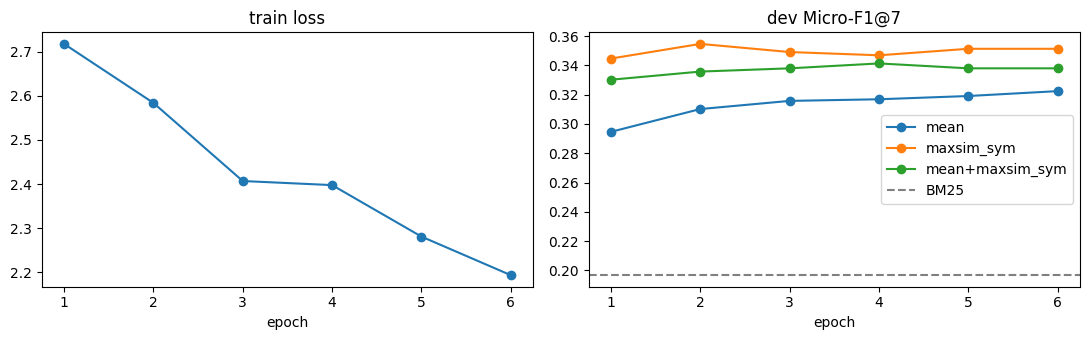

In [12]:
# ============================================================
# CELL 12: FINAL TRAINING
# ============================================================
FINAL_CFG = TrialCfg()
print("final config:", json.dumps(asdict(FINAL_CFG)))
json.dump(asdict(FINAL_CFG), open(OUT_DIR / "final_cfg.json", "w"), indent=1)
FINAL_PATH = OUT_DIR / "final_best_adapters.pt"
if RESUME and FINAL_PATH.exists() and (OUT_DIR / "final_run.json").exists():
    FINAL = json.load(open(OUT_DIR / "final_run.json")); print("finished final run found on disk -> skipping training")
else:
    FINAL = run_trial(FINAL_CFG, TRAIN_EXS, FINAL_EPOCHS, FINAL_EVAL_CHUNKS, save_path=FINAL_PATH)
    json.dump(FINAL, open(OUT_DIR / "final_run.json", "w"), indent=1, default=float)
print(f"\nBEST EPOCH = {FINAL['best_epoch']} | dev F1@7 = {FINAL['best_score']:.4f} ({FINAL['best_mode']}) | trainable {FINAL['trainable_params']/1e6:.3f}M")

import matplotlib.pyplot as plt
ep = [h["epoch"] for h in FINAL["history"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(ep, [h["loss"] for h in FINAL["history"]], marker="o"); ax[0].set_title("train loss"); ax[0].set_xlabel("epoch")
for n in ("mean", "maxsim_sym", "mean+maxsim_sym"):
    ax[1].plot(ep, [h["metrics"][n]["F1"] for h in FINAL["history"]], marker="o", label=n)
ax[1].axhline(ZERO_SHOT["bm25_dev"]["F1"], ls="--", c="gray", label="BM25"); ax[1].set_title("dev Micro-F1@7"); ax[1].legend(); ax[1].set_xlabel("epoch")
plt.tight_layout(); plt.savefig(OUT_DIR / "final_curves.png", dpi=130); plt.show()

In [13]:
# ============================================================
# CELL 14: BEST CHECKPOINT -> dev analysis at the full chunk cap + scoring-mode selection
# ============================================================
def load_final(path, grad_ckpt=False):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    cfg = TrialCfg(**ck["cfg"])
    model = PCRModel(cfg.pool, grad_ckpt=grad_ckpt, lora=tuple(ck["lora_spec"]))          # quantises the Phase 1 weights to NF4 again (deterministic)
    missing, unexpected = model.load_state_dict(ck["lora"], strict=False)
    assert not unexpected and all("lora_" not in k for k in missing), (unexpected[:3], missing[:3])
    return model.eval(), cfg, ck

final_model, final_cfg, final_ck = load_final(FINAL_PATH)
print("loaded best epoch", final_ck["epoch"])
dev_res = evaluate_split(final_model, "dev", TEST_EVAL_CHUNKS, return_scores=True)
DEV_SCORES = dev_res["scores"]
display(fmt_metrics(dev_res["metrics"]).sort_values("F1@7", ascending=False))
BEST_NEURAL = max(NEURAL_NAMES, key=lambda n: dev_res["metrics"][n]["F1"])
BEST_HYBRID = max([n for n in dev_res["metrics"] if n != "bm25"], key=lambda n: dev_res["metrics"][n]["F1"])
print(f"best neural-only scoring: {BEST_NEURAL}  F1@7={dev_res['metrics'][BEST_NEURAL]['F1']:.4f}")
print(f"best incl. BM25 fusion  : {BEST_HYBRID}  F1@7={dev_res['metrics'][BEST_HYBRID]['F1']:.4f}")

rows = {"BM25 (no learning)": ZERO_SHOT["bm25_dev"]}
if "fp32_base" in ZERO_SHOT:
    rows[f"Phase 1 MLA zero-shot, FP base (cap {ZERO_EVAL_CHUNKS})"] = ZERO_SHOT["fp32_base"]["metrics"][ZERO_SHOT["fp32_base"]["best_name"]]
    rows[f"Phase 1 MLA zero-shot, NF4 base (cap {ZERO_EVAL_CHUNKS})"] = ZERO_SHOT["nf4_base"]["metrics"][ZERO_SHOT["nf4_base"]["best_name"]]
rows["MLA + QLoRA (best neural)"] = dev_res["metrics"][BEST_NEURAL]
rows["MLA + QLoRA + BM25 fusion"] = dev_res["metrics"][BEST_HYBRID]
headline = pd.DataFrame(rows).T[["P", "R", "F1"]].round(4); display(headline)
headline.to_csv(OUT_DIR / "headline_dev.csv")

loaded best epoch 2


,P@7,R@7,F1@7
maxsim_sym,0.3850,0.3268,0.3535
maxsim_sym+0.25*bm25,0.3789,0.3217,0.3480
mean+maxsim_sym,0.3717,0.3155,0.3413
maxsim_sym+0.5*bm25,0.3535,0.3001,0.3246
maxsim,0.3535,0.3001,0.3246
mean,0.3414,0.2898,0.3135
mean+0.25*bm25,0.3354,0.2847,0.3079
mean+0.5*bm25,0.3220,0.2734,0.2957
maxsim_sym+1.0*bm25,0.3075,0.2610,0.2824
mean+1.0*bm25,0.2930,0.2487,0.2690


best neural-only scoring: maxsim_sym  F1@7=0.3535
best incl. BM25 fusion  : maxsim_sym  F1@7=0.3535


,P,R,F1
BM25 (no learning),0.2143,0.1819,0.1968
"Phase 1 MLA zero-shot, FP base (cap 12)",0.2845,0.2415,0.2613
"Phase 1 MLA zero-shot, NF4 base (cap 12)",0.2845,0.2415,0.2613
MLA + QLoRA (best neural),0.3850,0.3268,0.3535
MLA + QLoRA + BM25 fusion,0.3850,0.3268,0.3535


In [14]:
# ============================================================
# CELL 14b: FUSION + POOL-AWARE CALIBRATION, tuned on dev (from the improved GQA notebook)
# ============================================================
NEURAL = {"dev": {k: DEV_SCORES[k] for k in ("mean", "maxsim", "maxsim_sym")}}       # best-epoch EMA adapters, 48 chunks/doc
Gdev = GOLD["dev"]; ALL = np.arange(Gdev.shape[0])
print("neural only (dev F1@7):", {k: round(f1_at7(v, Gdev), 4) for k, v in NEURAL["dev"].items()})

def feats(split):
    return {"ms": rowz(NEURAL[split]["maxsim_sym"]), "mean": rowz(NEURAL[split]["mean"]), "lex": LEXF[split]}
def build_Z(Fz, wm, wl): return rowz(Fz["ms"] + wm * Fz["mean"] + wl * Fz["lex"])

WM, WL = (0, 0.25, 0.5), (0, 0.25, 0.5, 0.75, 1.0, 1.5, 2.0, 3.0)
CALS = CAL_GRID if USE_CALIBRATION else [("none", {})]
Fdev = feats("dev")
def grid_search(rows, cals):
    res = []
    for wm in WM:
        for wl in WL:
            Z = build_Z(Fdev, wm, wl)
            for m, p in cals:
                res.append((f1_at7(calibrate(Z, m, **p)[rows], Gdev[rows]), wm, wl, m, p))
    res.sort(key=lambda r: -r[0]); return res

res_all = grid_search(ALL, CALS); res_nocal = grid_search(ALL, [("none", {})])
abl = pd.DataFrame([
    {"system": "neural maxsim_sym only", "dev F1@7": f1_at7(NEURAL["dev"]["maxsim_sym"], Gdev)},
    {"system": "lexical suite only", "dev F1@7": f1_at7(LEXF["dev"], Gdev)},
    {"system": f"neural + lexical (w_mean={res_nocal[0][1]}, w_lex={res_nocal[0][2]})", "dev F1@7": res_nocal[0][0]},
    {"system": f"neural + lexical + calibration ({cal_name(res_all[0][3], res_all[0][4])})", "dev F1@7": res_all[0][0]}]).set_index("system")
display(abl.round(4)); abl.to_csv(OUT_DIR / "ablation_dev.csv")
print("top-5 settings (F1, w_mean, w_lex, calibration):")
for r in res_all[:5]: print("  ", round(r[0], 4), r[1], r[2], cal_name(r[3], r[4]))

# honest estimate: tune on half of the dev queries, score on the other half (repeated)
rs = np.random.RandomState(0); cv_tuned, cv_neural = [], []
for _ in range(5):
    perm = rs.permutation(len(ALL)); a, b = perm[:len(perm) // 2], perm[len(perm) // 2:]
    for tr, te in ((a, b), (b, a)):
        _, wm, wl, m, p = grid_search(tr, CALS)[0]
        cv_tuned.append(f1_at7(calibrate(build_Z(Fdev, wm, wl), m, **p)[te], Gdev[te])); cv_neural.append(f1_at7(Fdev["ms"][te], Gdev[te]))
print(f"cross-validated on dev: tuned fusion = {np.mean(cv_tuned):.4f}  vs  neural only = {np.mean(cv_neural):.4f}")

_, WM_, WL_, CM, CP = res_all[0]
json.dump({"w_mean": WM_, "w_lex": WL_, "calibration": CM, "cal_params": CP, "lexical_weights": LEXW, "bm25": BM25_BEST,
           "best_epoch": FINAL["best_epoch"]}, open(OUT_DIR / "fusion_params.json", "w"), indent=1)

neural only (dev F1@7): {'mean': 0.3135, 'maxsim': 0.3246, 'maxsim_sym': 0.3535}


,dev F1@7
system,
neural maxsim_sym only,0.3535
lexical suite only,0.3780
"neural + lexical (w_mean=0, w_lex=1.5)",0.3847
"neural + lexical + calibration (dsm(tau=0.6,alpha=1.25))",0.4503


top-5 settings (F1, w_mean, w_lex, calibration):
   0.4503 0 1.0 dsm(tau=0.6,alpha=1.25)
   0.4503 0 1.5 dsm(tau=0.6,alpha=1.25)
   0.4503 0 3.0 dsm(tau=1.0,alpha=1.25)
   0.4491 0 0.75 dsm(tau=0.6,alpha=1.25)
   0.4491 0 3.0 dsm(tau=1.0,alpha=1.5)
cross-validated on dev: tuned fusion = 0.4430  vs  neural only = 0.3537


In [15]:
# ============================================================
# CELL 15: ERROR ANALYSIS (gold-count / length / recall headroom / hubness)
# ============================================================
from scipy.stats import spearmanr
S = DEV_SCORES[BEST_NEURAL]; qk, ck = QKEYS["dev"], CKEYS["dev"]; ck_idx = {k: i for i, k in enumerate(ck)}
order = np.argsort(-S, axis=1); rows, all_ranks = [], []
for i, q in enumerate(qk):
    rank = np.empty(len(ck), int); rank[order[i]] = np.arange(len(ck))
    gold = REL["dev"][q]; gr = sorted(int(rank[ck_idx[g]]) for g in gold)
    hits = sum(r < TOP_K for r in gr); all_ranks += gr
    rows.append(dict(q=q, n_gold=len(gold), hits=hits, f1=2 * hits / (TOP_K + len(gold)), q_tokens=len(DOC_TOK[q]), best_gold_rank=gr[0]))
qa = pd.DataFrame(rows)
oracle_tp = sum(min(TOP_K, r) for r in qa.n_gold); Po, Ro = oracle_tp / (TOP_K * len(qa)), oracle_tp / qa.n_gold.sum()
print(f"Oracle micro-F1@7 = {2*Po*Ro/(Po+Ro):.4f}")
qa["gold_bucket"] = pd.cut(qa.n_gold, [0, 1, 3, 7, 15, 1000], labels=["1", "2-3", "4-7", "8-15", "16+"])
display(qa.groupby("gold_bucket").agg(queries=("q", "size"), hits=("hits", "mean"), f1=("f1", "mean")).round(3))
qa["len_bucket"] = pd.qcut(qa.q_tokens, 4, labels=["shortest", "short-mid", "long-mid", "longest"])
display(qa.groupby("len_bucket").agg(tokens=("q_tokens", "median"), hits=("hits", "mean"), f1=("f1", "mean")).round(3))
print("Spearman(query tokens, hits) = %.3f (p=%.3f)" % spearmanr(qa.q_tokens, qa.hits), "| zero-hit queries:", int((qa.hits == 0).sum()), "/", len(qa))
all_ranks = np.array(all_ranks)
print("Recall@k over gold pairs:", {k: round(float((all_ranks < k).mean()), 3) for k in (7, 10, 20, 50, 100)})
cnt = np.bincount(order[:, :TOP_K].ravel(), minlength=len(ck)); c_len = np.array([len(DOC_TOK[k]) for k in ck])
print("hubness: never retrieved %d/%d | max appearances %d | Spearman(candidate length, #retrieved) = %.3f" % ((cnt == 0).sum(), len(ck), cnt.max(), spearmanr(c_len, cnt)[0]))
qa.to_csv(OUT_DIR / "dev_error_analysis.csv", index=False)

Oracle micro-F1@7 = 0.6181


,queries,hits,f1
gold_bucket,,,
1,15,0.733,0.183
2-3,25,1.560,0.336
4-7,39,2.641,0.422
8-15,25,4.120,0.466
16+,14,4.429,0.272


,tokens,hits,f1
len_bucket,,,
shortest,3909.5,1.600,0.293
short-mid,7275.0,2.621,0.421
long-mid,12291.0,3.414,0.442
longest,27175.5,3.167,0.308


Spearman(query tokens, hits) = 0.411 (p=0.000) | zero-hit queries: 11 / 118
Recall@k over gold pairs: {7: 0.327, 10: 0.396, 20: 0.523, 50: 0.665, 100: 0.744}
hubness: never retrieved 446/1023 | max appearances 5 | Spearman(candidate length, #retrieved) = -0.034


In [16]:
# ============================================================
# CELL 16: LONG-DOCUMENT ABLATION — chunks per document at inference (512-token chunks)
# ============================================================
if RUN_CAP_ABLATION:
    rows = []
    for cap in (2, 4, 8, 16, 32, 48):
        r = evaluate_split(final_model, "dev", cap, fusion=False)
        rows.append({"max chunks/doc": cap, "mean F1": r["metrics"]["mean"]["F1"], "maxsim_sym F1": r["metrics"]["maxsim_sym"]["F1"],
                     "total chunks": r["n_chunks"]})
    cap_table = pd.DataFrame(rows).set_index("max chunks/doc").round(4); display(cap_table); cap_table.to_csv(OUT_DIR / "cap_ablation.csv")

,mean F1,maxsim_sym F1,total chunks
max chunks/doc,,,
2,0.2201,0.2112,2264
4,0.2757,0.2724,4437
8,0.2957,0.3224,8434
16,0.3079,0.3457,14883
32,0.3102,0.3546,22511
48,0.3135,0.3535,26515


In [17]:
# ============================================================
# CELL 17: TEST INFERENCE -> prediction.json (neural + lexical + calibration), EXPORT .pt FILES, RELOAD CHECK
# ============================================================
import shutil
def write_prediction(S, path, tag):
    pred = topk_keys(S, QKEYS["test"], CKEYS["test"], TOP_K)
    pool_ids = {cid_of(k) for k in CKEYS["test"]}
    out = {cid_of(q): [cid_of(c) for c in cs] for q, cs in pred.items()}
    assert len(out) == len(QKEYS["test"])
    for q, cs in out.items():
        assert len(cs) == TOP_K and len(set(cs)) == TOP_K and all(c in pool_ids for c in cs), q
    json.dump(out, open(path, "w"), indent=1)
    print(f"[{tag}] wrote {Path(path).name} | {len(out)} queries x {TOP_K} unique candidates, all from the test pool")

q_emb, q_offs = encode_docs(final_model, QKEYS["test"], TEST_EVAL_CHUNKS); c_emb, c_offs = encode_docs(final_model, CKEYS["test"], TEST_EVAL_CHUNKS)
test_neural = score_neural(q_emb, q_offs, c_emb, c_offs)
variants = add_fusions(test_neural, BM25["test"])
TEST_STATS = dict(n_chunks=int(q_offs[-1] + c_offs[-1]), index_mb=(c_offs[-1] * P1_CFG.d_model * 2) / 1024**2)
NEURAL["test"] = {k: test_neural[k] for k in ("mean", "maxsim", "maxsim_sym")}
del q_emb, c_emb; torch.cuda.empty_cache()

# fused system (tuned on dev in CELL 14b): neural + tuned lexical suite + pool-aware calibration
Ftest = feats("test"); Zt = build_Z(Ftest, WM_, WL_); S_final = calibrate(Zt, CM, **CP)
write_prediction(S_final, OUT_DIR / "prediction.json", "SUBMIT: neural + lexical + calibration")
write_prediction(Zt, OUT_DIR / "prediction_neural_lexical_nocal.json", "neural + lexical")
write_prediction(variants[BEST_NEURAL], OUT_DIR / "prediction_neural.json", f"neural only:{BEST_NEURAL}")
write_prediction(variants[BEST_HYBRID], OUT_DIR / "prediction_hybrid.json", f"neural + plain BM25:{BEST_HYBRID}")
shutil.copy(OUT_DIR / "prediction.json", "/kaggle/working/prediction.json")                  # <- submission file
ADAPTERS_PT = OUT_DIR / "mla_qlora_best_adapters.pt"; NF4_MODEL_PT = OUT_DIR / "mla_qlora_nf4_model.pt"
shutil.copy(FINAL_PATH, ADAPTERS_PT)                                                                       # <- LoRA adapters (small) + config
# full self-contained retrieval model: NF4-packed base (uint8 codes + int8/fp32 double-quant scales) + FP32 adapters + embedding / norms
torch.save({"model_state_dict": final_model.state_dict(), "model_config": asdict(P1_CFG), "lora_spec": tuple(final_ck["lora_spec"]),
            "pool": final_cfg.pool, "scoring": BEST_NEURAL, "train_cfg": asdict(final_cfg), "best_epoch": final_ck["epoch"],
            "nf4": {"block": NF4_BLOCK, "dq_block": DQ_BLOCK, "levels": NF4_LEVELS},
            "note": "Phase 1 MLA decoder, block linears stored in NF4 (double quant) + trained LoRA adapters (EMA); load with load_qlora_model()"},
           NF4_MODEL_PT)                                                                                   # <- full model

def load_qlora_model(path):
    ck = torch.load(path, map_location="cpu", weights_only=False)
    m = PCRModel(ck["pool"], grad_ckpt=False, lora=tuple(ck["lora_spec"]), init_p1=False)               # skeleton; every tensor is overwritten below
    m.load_state_dict(ck["model_state_dict"], strict=True)
    return m.eval(), ck

# reload check: a fresh model built ONLY from the exported file must reproduce the trained model
reloaded, _ck = load_qlora_model(NF4_MODEL_PT)
_arrs = [make_chunk(DOC_TOK[CKEYS["dev"][i]][:CONTENT_LEN]) for i in range(24)]; _ids, _mk = pad_batch(_arrs)
with torch.no_grad(), torch.autocast("cuda", dtype=AMP_DTYPE):
    _a = final_model(_ids.to(device), _mk.to(device)).float(); _b = reloaded(_ids.to(device), _mk.to(device)).float()
cos = F.cosine_similarity(_a, _b).min().item(); print(f"reloaded model vs trained model: min cosine = {cos:.6f}"); assert cos > 0.9999
del reloaded; gc.collect(); torch.cuda.empty_cache()
for p in (OUT_DIR / "prediction.json", ADAPTERS_PT, NF4_MODEL_PT):
    print(f"{p.name:40s} {os.path.getsize(p)/1024**2:8.1f} MB")
print("\nsubmit /kaggle/working/prediction.json (also saved in", OUT_DIR, ")")

[SUBMIT: neural + lexical + calibration] wrote prediction.json | 237 queries x 7 unique candidates, all from the test pool
[neural + lexical] wrote prediction_neural_lexical_nocal.json | 237 queries x 7 unique candidates, all from the test pool
[neural only:maxsim_sym] wrote prediction_neural.json | 237 queries x 7 unique candidates, all from the test pool
[neural + plain BM25:maxsim_sym] wrote prediction_hybrid.json | 237 queries x 7 unique candidates, all from the test pool
reloaded model vs trained model: min cosine = 1.000000
prediction.json                               0.0 MB
mla_qlora_best_adapters.pt                   14.1 MB
mla_qlora_nf4_model.pt                      210.8 MB

submit /kaggle/working/prediction.json (also saved in /kaggle/working/pcr_mla_qlora )


In [18]:
# ============================================================
# CELL 18: EFFICIENCY REPORT + EXPERIMENT SUMMARY
# ============================================================
sr = storage_report(final_model)
n_params = count_params(final_model); n_train = count_params(final_model, True)
eff = {
    "total_params_M (incl. adapters)": n_params / 1e6,
    "trainable_params_M (LoRA)": n_train / 1e6,
    "trainable_fraction_%": 100 * n_train / n_params,
    "block-linear weights FP16_MB": sr["fp16_MB"],
    "block-linear weights NF4+DQ_MB": sr["nf4_MB"],
    "bits_per_param (NF4+DQ)": sr["bits_per_param"],
    "compression_vs_FP16_x": sr["compression_vs_fp16"],
    "adapter_file_MB": os.path.getsize(ADAPTERS_PT) / 1024**2,
    "full_nf4_model_file_MB": os.path.getsize(NF4_MODEL_PT) / 1024**2,
    "test_pool_index_MB (fp16 chunk vectors)": TEST_STATS["index_mb"],
    "chunk_length": CHUNK_LEN,
}
display(pd.Series(eff).round(2).to_frame("value"))
summary = {"experiment": "Phase1 MLA decoder + QLoRA (NF4 + double quant + LoRA, scratch)", "zero_shot": ZERO_SHOT,
           "final_cfg": asdict(FINAL_CFG), "final_history": FINAL["history"], "best_epoch": FINAL["best_epoch"],
           "dev_final": dev_res["metrics"], "best_neural": BEST_NEURAL, "best_hybrid": BEST_HYBRID, "efficiency": eff,
           "fusion": {"w_mean": WM_, "w_lex": WL_, "calibration": CM, "cal_params": CP, "lexical_weights": LEXW, "dev_F1_fused": float(res_all[0][0]),
                      "cv_tuned": float(np.mean(cv_tuned)), "cv_neural_only": float(np.mean(cv_neural))}}
json.dump(summary, open(OUT_DIR / "experiment3_summary.json", "w"), indent=1, default=float)
print("saved:", OUT_DIR / "experiment3_summary.json")

,value
total_params_M (incl. adapters),42.11
trainable_params_M (LoRA),3.69
trainable_fraction_%,8.75
block-linear weights FP16_MB,193.50
block-linear weights NF4+DQ_MB,49.91
bits_per_param (NF4+DQ),4.13
compression_vs_FP16_x,3.88
adapter_file_MB,14.14
full_nf4_model_file_MB,210.83
test_pool_index_MB (fp16 chunk vectors),57.82


saved: /kaggle/working/pcr_mla_qlora/experiment3_summary.json


## How this maps onto the Section 13.5 analysis questions
| Report question | Evidence |
|---|---|
| Effect of the adaptation technique (QLoRA) | headline table (CELL 14) vs. zero-shot FP / NF4 / BM25 and vs. Exp. 1 full-FT; trainable-parameter fraction and file sizes (CELL 18) |
| What 4-bit quantisation costs | zero-shot FP-base vs NF4-base rows (CELL 9); relative weight error / chunk-embedding cosine (CELL 7); QLoRA vs the FP16 base after training |
| How Phase 1 (MLA) representations transfer | zero-shot row vs. tuned row (CELL 9/14) |
| Pooling & document representation | pooling carried over from Exp. 1; mean vs MaxSim vs fused (CELL 14); chunks/doc at inference (CELL 16) |
| Negatives / ranking objective | carried over from Exp. 1 (BM25 hard negatives + InfoNCE + false-negative masking), not re-searched |
| Long legal documents | CELL 5 chunk statistics, CELL 15 length buckets, CELL 16 ablation |
| Failure patterns | CELL 15 |
| Quality vs. size / memory / speed | CELL 18 table: base weights 4.1x smaller, only 3-4 M trainable parameters, adapter / full-model file sizes |
| Lexical + calibration (system on top of the model) | CELL 5b (lexical suite), CELL 14b (ablation table: neural / lexical / fused / calibrated, split-half cross-check) |